# Patrones electorales de las comunas y mirada a 2027
### Observatorio de Dinámicas Electorales de Barrancabermeja

**Laura Pérez · Ciencia de datos** — @layape
Cuaderno 06 · Proyecto personal

---

## Objetivo

Responder, con los datos oficiales, las preguntas que surgieron tras publicar el primer análisis del Concejo:

1. **Local vs. nacional.** ¿Barranca participa distinto en elecciones locales (Alcaldía, Concejo) que en las nacionales más recientes (Congreso 2022, Presidencia 2026)? ¿Son comparables?
2. **Voto diferenciado.** Dentro de cada comuna, de quienes votan Concejo, ¿cuántos también votan Alcaldía? ¿Hay quien vota solo Alcaldía y deja el Concejo?
3. **Mirada a 2027.** Con el comportamiento observado y el censo actual, ¿qué escenarios razonables hay para las territoriales de 2027, y hacia dónde se está moviendo el electorado?
4. **Retrato integral.** Cruzar participación, abstención, censo y perfil etario por comuna, con lente de 2027.
5. **Anatomía de las listas (sección 8).** ¿Qué combinación de candidatos produce una curul y cuál no? Si alguien arma una lista, ¿cuántos de cada tipo necesita? Si alguien quiere ganar un puesto, ¿en qué lista le conviene entrar?
6. **El sistema de partidos (sección 9).** ¿La etiqueta arrastra voto propio? ¿Hay comunas fieles a una marca? ¿Se está fragmentando la competencia?

## Convenciones de rigor

Cada hallazgo declara su **nivel de evidencia**:

| Nivel | Significado |
|---|---|
| **A — Hecho** | Se lee directo del dato oficial; no admite interpretación. |
| **B — Inferencia sólida** | Se deriva de un cálculo reproducible sobre el dato (p. ej. cifra repartidora, correlación). |
| **C — Escenario** | Proyección condicionada a supuestos explícitos. **No es un pronóstico.** |

Reglas que se respetan en todo el cuaderno:

- Todo sale de datos **públicos y oficiales** (Registraduría / CNE). Procesamiento propio y reproducible.
- **Ningún patrón se reporta agregando los dos ciclos territoriales.** Cada regularidad se verifica en 2019 **y** en 2023 por separado; la que no se cumple en ambos se marca como *no replicada* y no sustenta ninguna recomendación. Se declara siempre el número de casos.
- **Los resultados nulos se reportan igual que los positivos**, para no quedarse solo con lo que confirma la hipótesis.
- Los análisis por comuna son **agregados (ecológicos)**: describen el comportamiento del *territorio*, nunca el voto de una persona identificable (el voto es secreto).
- No se imputan datos faltantes; cuando una fuente tiene cobertura parcial, se anota la salvedad.


In [1]:
# --- Configuración, rutas y utilidades -------------------------------------
%matplotlib inline
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
try:
    from scipy.stats import spearmanr, pearsonr
    HAVE_SCIPY = True
except Exception:
    HAVE_SCIPY = False

# Localiza la raíz del proyecto subiendo desde la ubicación del cuaderno
def find_root(start):
    for cand in [Path(start).resolve(), *Path(start).resolve().parents]:
        if (cand / "datos" / "analitico" / "agregado_territorio.csv").exists():
            return cand
    raise FileNotFoundError("No encuentro datos/analitico/ subiendo desde " + str(start))

try:    HERE = Path(__file__).parent          # ejecución por script
except NameError: HERE = Path.cwd()           # ejecución interactiva
ROOT  = find_root(HERE)
ANAL  = ROOT / "datos" / "analitico"
PROC  = ROOT / "datos" / "procesados"
R26   = ROOT / "datos" / "intermedios" / "registraduria" / "2026"
URB   = [f"COMUNA {i}" for i in range(1, 8)]

# Paleta del Observatorio (coherente con el carrusel)
INK, VERM, OCHRE, TEAL, MUTED, PAPER = "#14100D", "#E24B2E", "#E3A008", "#1C8A6E", "#9A9288", "#F5F1E8"
# Paleta validada para daltonismo: TEAL↔VERM ΔE=9.5 (protan), suelo de croma y
# de visión normal superados. Donde TEAL y VERM coexisten siempre hay además
# etiqueta directa, nunca color solo.
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#B9B2A6", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#E6E1D6", "grid.linewidth": .8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12,
})
def comuna_colors(highlight="COMUNA 2"):
    return [VERM if c == highlight else "#6B6358" for c in URB]

print("Proyecto :", ROOT)
print("pandas", pd.__version__, "| scipy disponible:", HAVE_SCIPY)
print("Datos analíticos encontrados:", (ANAL/'agregado_territorio.csv').exists())


Proyecto : D:\Users\LAURA PEREZ\Desktop\CIENCIA DE DATOS\Proy_Electoral_Bca
pandas 3.0.6 | scipy disponible: True
Datos analíticos encontrados: True


## 1. Fuentes y cobertura

El cuaderno cruza tres familias electorales. Antes de comparar, conviene fijar qué hay y con qué cobertura, porque **no todas las elecciones son igual de comparables**.


In [2]:
# Inventario de elecciones disponibles y su cobertura
ae = pd.read_csv(ANAL / "agregado_eleccion.csv")
inv = (ae[["anio","familia","corporacion","potencial_electoral","votos_depositados",
           "participacion","cobertura_del_censo","potencial_es_del_distrito_completo"]]
       .sort_values(["familia","anio","corporacion"]).reset_index(drop=True))
inv["potencial_electoral"] = inv["potencial_electoral"].astype(int)
inv.rename(columns={"cobertura_del_censo":"cobertura_%",
                    "potencial_es_del_distrito_completo":"distrito_completo"}, inplace=True)
inv


,anio,familia,corporacion,potencial_electoral,votos_depositados,participacion,cobertura_%,distrito_completo
0,2022,congreso,CAMARA,166797,100605,60.32,90.2,False
1,2022,congreso,SENADO,166797,101430,60.81,90.2,False
2,2019,territorial,ALCALDE,175303,121980,69.58,100.0,True
3,2019,territorial,ASAMBLEA,175303,119968,68.43,100.0,True
4,2019,territorial,CONCEJO,175303,121765,69.46,100.0,True
5,2019,territorial,GOBERNADOR,175303,120891,68.96,100.0,True
6,2019,territorial,JAL,175106,116070,66.29,100.0,True
7,2023,territorial,ALCALDE,187483,132133,70.48,100.0,True
8,2023,territorial,ASAMBLEA,187483,128983,68.80,100.0,True
9,2023,territorial,CONCEJO,187483,131961,70.39,100.0,True


**Lo que usamos y por qué — panorama completo:**

- **Local (territorial):** Alcaldía y Concejo **2019** y **2023**. Cobertura 100 %, mismo día de votación → base más limpia y eje del análisis.
- **Nacional:** se incluye **toda** la oferta nacional disponible para poder comparar y ver la tendencia, priorizando siempre **la más reciente**:
  - **Congreso 2022** (Senado/Cámara) — las legislativas se celebran cada 4 años (2022 y 2026; **no hubo elección de Congreso en 2025**).
  - **Congreso 2026** (Senado/Cámara) — la legislativa **más reciente**, computada en este cuaderno desde el escrutinio por mesa de la Registraduría.
  - **Presidencia 2026** (1.ª y 2.ª vuelta) — la elección nacional más reciente de todas.
- **Salvedad de Congreso 2022:** a nivel *ciudad* la participación de distrito completo es ~60 %; al desagregar por comuna, ~6 puestos quedan sin comuna asignada (cobertura ≈ 92 %), así que **su nivel por comuna se usa solo como referencia**. El **Congreso 2026** y la **Presidencia 2026** sí traen mapeo completo por comuna (DIVIPOL), así que son la referencia nacional fina.


## 2. ¿Vota distinto Barranca en lo local y en lo nacional?

Primero el retrato de ciudad: participación por elección, usando siempre la cifra de **distrito completo** (la comparable).


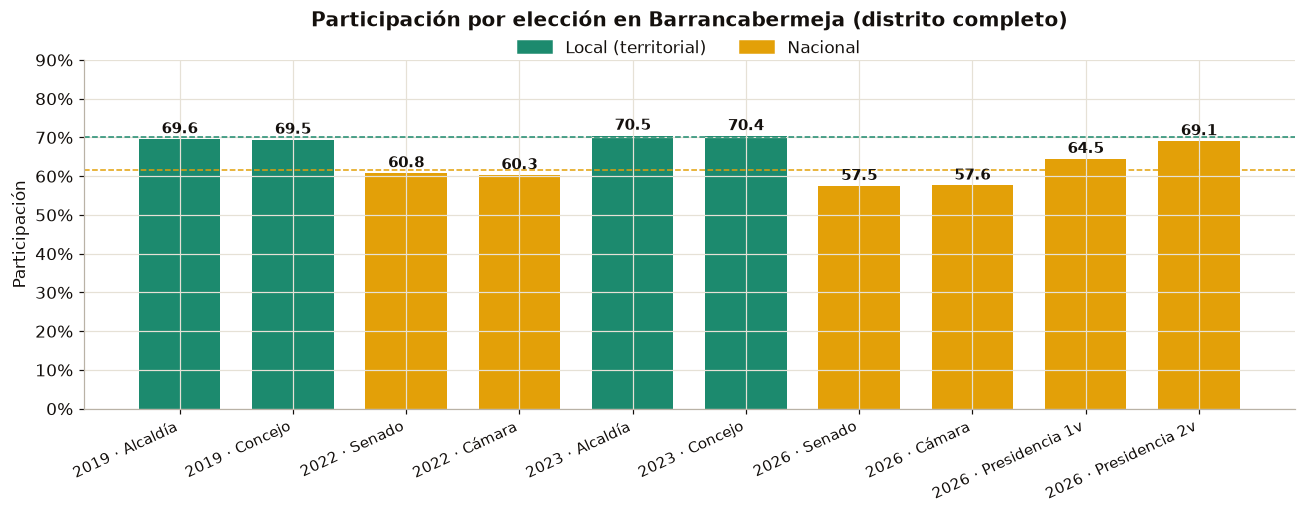

Promedio participación  LOCAL : 70.0%
Promedio participación NACIONAL: 61.6%


In [3]:
# Serie ciudad: participación por elección (distrito completo)
def pres_city(v):
    esc = pd.read_csv(R26 / f"presidencia_2026_{v}_escrutinio_barrancabermeja.csv", dtype=str)
    dep = pd.to_numeric(esc["votos"], errors="coerce").fillna(0).sum()
    dvf = next(p for p in [R26/f"presidencia_2026_{v}_divipol_barrancabermeja.csv",
                           R26/f"presidencia_2026_{v}_divipol_local_barrancabermeja.csv"] if p.exists())
    dv  = pd.read_csv(dvf, dtype=str)
    pot = (pd.to_numeric(dv.potencial_hombres,errors="coerce").fillna(0)
         + pd.to_numeric(dv.potencial_mujeres,errors="coerce").fillna(0)).sum()
    return dep/pot*100

def part_ciudad(anio, corp):
    return float(ae.query("anio==@anio & corporacion==@corp").participacion.iloc[0])
# Congreso 2026 (computado aparte y guardado como agregado liviano)
cong26 = pd.read_csv(PROC/"participacion"/"participacion_congreso_2026.csv")
def cong_city(corp):
    return float(cong26.query("nivel=='ciudad' & corporacion==@corp").participacion.iloc[0])

serie = [
    ("2019", "Local",    "Alcaldía",       part_ciudad(2019,"ALCALDE")),
    ("2019", "Local",    "Concejo",        part_ciudad(2019,"CONCEJO")),
    ("2022", "Nacional", "Senado",         part_ciudad(2022,"SENADO")),
    ("2022", "Nacional", "Cámara",         part_ciudad(2022,"CAMARA")),
    ("2023", "Local",    "Alcaldía",       part_ciudad(2023,"ALCALDE")),
    ("2023", "Local",    "Concejo",        part_ciudad(2023,"CONCEJO")),
    ("2026", "Nacional", "Senado",         cong_city("SENADO")),
    ("2026", "Nacional", "Cámara",         cong_city("CAMARA")),
    ("2026", "Nacional", "Presidencia 1v", pres_city("1v")),
    ("2026", "Nacional", "Presidencia 2v", pres_city("2v")),
]
S = pd.DataFrame(serie, columns=["año","ámbito","elección","participación"])
S["etiqueta"] = S["año"] + " · " + S["elección"]

fig, ax = plt.subplots(figsize=(12, 4.8))
colors = [TEAL if a=="Local" else OCHRE for a in S["ámbito"]]
bars = ax.bar(S["etiqueta"], S["participación"], color=colors, width=.72)
ax.axhline(S.query("ámbito=='Local'").participación.mean(), color=TEAL, ls="--", lw=1)
ax.axhline(S.query("ámbito=='Nacional'").participación.mean(), color=OCHRE, ls="--", lw=1)
for b,v in zip(bars, S["participación"]):
    ax.text(b.get_x()+b.get_width()/2, v+0.6, f"{v:.1f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax.set_ylim(0, 90); ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_ylabel("Participación"); ax.set_title("Participación por elección en Barrancabermeja (distrito completo)", pad=22)
ax.set_xticklabels(S["etiqueta"], rotation=25, ha="right", fontsize=9.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=TEAL,label="Local (territorial)"), Patch(color=OCHRE,label="Nacional")],
          loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.10), frameon=False)
plt.tight_layout(); plt.show()

prom_local = S[S["ámbito"]=="Local"]["participación"].mean()
prom_nac   = S[S["ámbito"]=="Nacional"]["participación"].mean()
print(f"Promedio participación  LOCAL : {prom_local:.1f}%")
print(f"Promedio participación NACIONAL: {prom_nac:.1f}%")


**Hallazgo 1 — Barranca se moviliza más por lo local que por lo nacional, y la legislativa es la que menos arrastra (y cayendo).** `Nivel A/B`

Con el panorama completo el patrón es nítido. La participación territorial (Alcaldía/Concejo) ronda el **70 %** en 2019 y 2023. En lo nacional:
- **Legislativas (Congreso):** **~60 %** en 2022 y **~57,6 %** en 2026 — las de **menor** participación, y **a la baja**.
- **Presidencia 2026:** **64,5 %** en 1.ª vuelta y **69,1 %** en 2.ª — sube, hasta casi igualar lo local.

Orden de arrastre: **Local ≈ Presidencial 2v > Presidencial 1v > Legislativas**. La contienda local moviliza tanto como la gran final presidencial y claramente más que el Congreso.

*Lo que NO significa:* que sea así en todo el país (el patrón nacional suele ser el inverso). Es un rasgo **propio de Barranca**, consistente en varios ciclos.


## 3. Participación por comuna y estabilidad del patrón

¿El mapa de quién participa y quién se abstiene es estable entre elecciones, o cambia según el tipo de contienda?


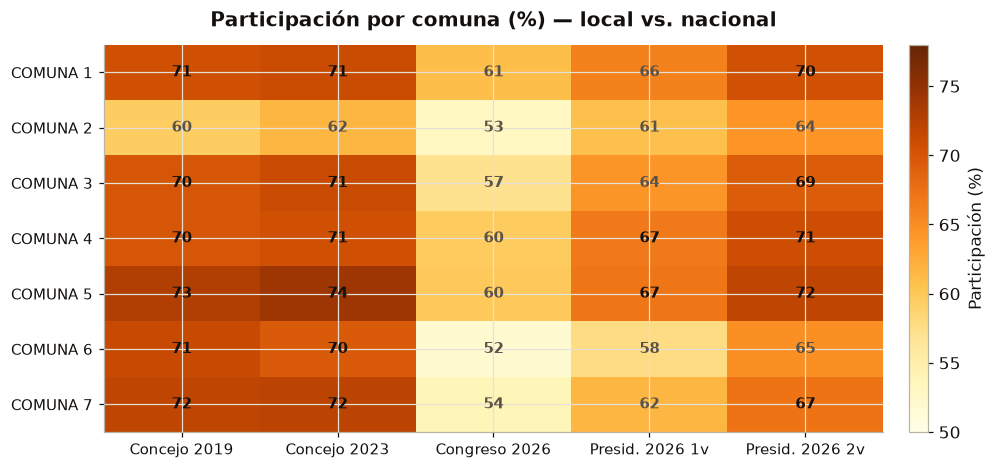

,Concejo 2019,Concejo 2023,Congreso 2026,Presid. 2026 1v,Presid. 2026 2v,Congreso 2022*
COMUNA 1,70.6,71.1,60.9,66.0,70.4,58.0
COMUNA 2,59.5,61.6,52.9,60.8,64.4,49.2
COMUNA 3,70.0,71.2,57.1,64.3,69.3,56.2
COMUNA 4,70.0,70.6,59.7,66.6,70.8,57.9
COMUNA 5,72.8,74.1,59.9,66.9,71.8,58.2
COMUNA 6,71.3,69.5,51.8,57.7,64.7,51.4
COMUNA 7,71.8,72.0,53.8,61.6,67.2,53.6


Spearman  Concejo2019 ↔ Concejo2023     : 0.72
Spearman  Concejo2023 ↔ Congreso2026    : 0.54
Spearman  Concejo2023 ↔ Presidencia2026 : 0.61


In [4]:
# Matriz de participación por comuna (elecciones con cobertura limpia por comuna)
at = pd.read_csv(ANAL / "agregado_territorio.csv")
at = at[at.ambito == "urbano"].copy()
def part(anio, corp):
    d = at[(at.anio==anio) & (at.corporacion==corp)].set_index("territorio")
    return (d.votos_depositados / d.potencial_electoral * 100).reindex(URB)

def pres_comuna(v):
    esc = pd.read_csv(R26 / f"presidencia_2026_{v}_escrutinio_barrancabermeja.csv", dtype=str)
    esc["votos"] = pd.to_numeric(esc["votos"], errors="coerce").fillna(0)
    dep = esc.groupby("comuna_divipol")["votos"].sum()
    dvf = next(p for p in [R26/f"presidencia_2026_{v}_divipol_barrancabermeja.csv",
                           R26/f"presidencia_2026_{v}_divipol_local_barrancabermeja.csv"] if p.exists())
    dv  = pd.read_csv(dvf, dtype=str)
    pot = (pd.to_numeric(dv.potencial_hombres,errors="coerce").fillna(0)
         + pd.to_numeric(dv.potencial_mujeres,errors="coerce").fillna(0))
    pot = pot.groupby(dv.comuna_divipol).sum()
    return (dep/pot*100).reindex(URB)

cong26 = pd.read_csv(PROC/"participacion"/"participacion_congreso_2026.csv")
c26 = cong26.query("nivel=='comuna' & corporacion=='SENADO'").set_index("territorio").participacion.reindex(URB)
M = pd.DataFrame({
    "Concejo 2019": part(2019,"CONCEJO"), "Concejo 2023": part(2023,"CONCEJO"),
    "Congreso 2026": c26,
    "Presid. 2026 1v": pres_comuna("1v"), "Presid. 2026 2v": pres_comuna("2v"),
}).round(1)
M["Congreso 2022*"] = part(2022,"SENADO").round(1)   # referencia, cobertura ~92%

# Heatmap (local + nacional más reciente, todas con cobertura limpia por comuna)
cols = ["Concejo 2019","Concejo 2023","Congreso 2026","Presid. 2026 1v","Presid. 2026 2v"]
fig, ax = plt.subplots(figsize=(9.2, 4.4))
data = M[cols].values
im = ax.imshow(data, cmap="YlOrBr", aspect="auto", vmin=50, vmax=78)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, fontsize=10)
ax.set_yticks(range(len(URB))); ax.set_yticklabels(URB, fontsize=10)
for i in range(len(URB)):
    for j in range(len(cols)):
        ax.text(j, i, f"{data[i,j]:.0f}", ha="center", va="center",
                color=INK if data[i,j] > 66 else "#5B5347", fontsize=10, fontweight="bold")
ax.set_title("Participación por comuna (%) — local vs. nacional")
cb = fig.colorbar(im, ax=ax, fraction=.045, pad=.03); cb.set_label("Participación (%)")
plt.tight_layout(); plt.show()

display(M)

# Estabilidad del ranking
if HAVE_SCIPY:
    r1 = spearmanr(M["Concejo 2019"], M["Concejo 2023"]).correlation
    r2 = spearmanr(M["Concejo 2023"], M["Congreso 2026"]).correlation
    r3 = spearmanr(M["Concejo 2023"], M["Presid. 2026 1v"]).correlation
    print(f"Spearman  Concejo2019 ↔ Concejo2023     : {r1:.2f}")
    print(f"Spearman  Concejo2023 ↔ Congreso2026    : {r2:.2f}")
    print(f"Spearman  Concejo2023 ↔ Presidencia2026 : {r3:.2f}")


**Hallazgo 2 — El mapa de la abstención es estructural, no coyuntural.** `Nivel B`

El orden de las comunas por participación se **repite elección tras elección y a través de niveles** (Spearman Concejo 2019↔2023 ≈ **0,72**; Concejo 2023 ↔ Congreso 2026 y ↔ Presidencia 2026, positivos). La **Comuna 2 es la de menor participación en TODAS** las contiendas —local, legislativa y presidencial (53 % en Congreso 2026)—, y la 5 suele liderar. Quien se abstiene en lo local tiende a abstenerse también en lo nacional.

*Lo que NO significa:* que sean las mismas personas cada vez (es patrón de territorio, no de individuos). El **nivel** sí cambia con el tipo de elección; el **orden** es el que se mantiene.


## 4. ¿Se vota Alcaldía sin votar Concejo? (voto diferenciado)

Alcaldía y Concejo se votan **el mismo día**, con tarjetas separadas. Podemos medir, de forma agregada, dos cosas: cuántas personas depositaron la tarjeta de Alcaldía pero no la de Concejo (*roll-off* de participación), y cuántas sí la depositaron pero la dejaron en blanco o nula (*roll-off* de voto válido).


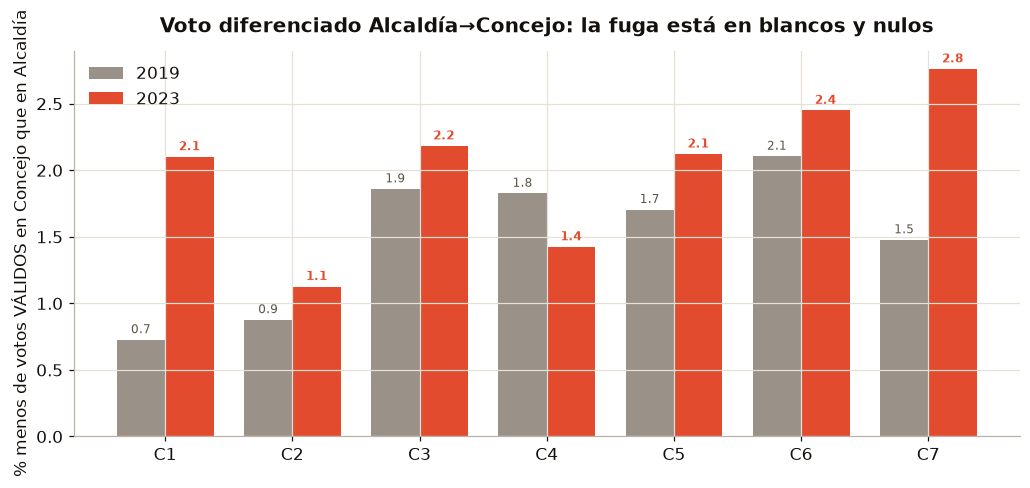

2019  roll-off DEPOSITADOS = 0.18%  |  roll-off VÁLIDOS = 1.46%  (1,546 tarjetas)
2023  roll-off DEPOSITADOS = 0.15%  |  roll-off VÁLIDOS = 2.00%  (2,265 tarjetas)


In [5]:
# Roll-off Alcaldía vs Concejo por comuna y año
def rolloff(y):
    a = at[(at.anio==y)&(at.corporacion=="ALCALDE")].set_index("territorio").reindex(URB)
    c = at[(at.anio==y)&(at.corporacion=="CONCEJO")].set_index("territorio").reindex(URB)
    return pd.DataFrame({
        "dep_dif_%": ((a.votos_depositados - c.votos_depositados)/a.votos_depositados*100),
        "val_dif_%": ((a.votos_validos    - c.votos_validos)   /a.votos_validos*100),
    })
ro19, ro23 = rolloff(2019), rolloff(2023)

fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(len(URB)); w = .38
ax.bar(x-w/2, ro19["val_dif_%"], w, color=MUTED, label="2019")
ax.bar(x+w/2, ro23["val_dif_%"], w, color=VERM,  label="2023")
ax.set_xticks(x); ax.set_xticklabels([c.replace('COMUNA ','C') for c in URB])
ax.set_ylabel("% menos de votos VÁLIDOS en Concejo que en Alcaldía")
ax.set_title("Voto diferenciado Alcaldía→Concejo: la fuga está en blancos y nulos")
ax.legend(frameon=False)
for xi, v in zip(x-w/2, ro19["val_dif_%"]): ax.text(xi, v+.05, f"{v:.1f}", ha="center", fontsize=8, color="#5B5347")
for xi, v in zip(x+w/2, ro23["val_dif_%"]): ax.text(xi, v+.05, f"{v:.1f}", ha="center", fontsize=8, color=VERM, fontweight="bold")
plt.tight_layout(); plt.show()

# Totales ciudad
for y, ro in [(2019, ro19), (2023, ro23)]:
    a = at[(at.anio==y)&(at.corporacion=="ALCALDE")]; c = at[(at.anio==y)&(at.corporacion=="CONCEJO")]
    dep = (a.votos_depositados.sum()-c.votos_depositados.sum())
    val = (a.votos_validos.sum()-c.votos_validos.sum())
    print(f"{y}  roll-off DEPOSITADOS = {dep/a.votos_depositados.sum()*100:.2f}%  |  "
          f"roll-off VÁLIDOS = {val/a.votos_validos.sum()*100:.2f}%  ({int(val):,} tarjetas)")


**Hallazgo 3 — Casi nadie vota "solo Alcaldía": el que va, vota todo. La diferencia está en cómo marca el Concejo.** `Nivel A/B`

En depositar la tarjeta, el *roll-off* es **mínimo** (0,15–0,18 %): quien va a las urnas deposita tanto la de Alcaldía como la de Concejo. Pero el Concejo recibe **~2 % menos votos válidos** que la Alcaldía (1,46 % en 2019 → **2,00 % en 2023**, unas **2.265 tarjetas** en 2023): más gente deja el Concejo en blanco o lo anula. La brecha **creció** entre 2019 y 2023.

*Lo que NO significa:* no podemos identificar personas (voto secreto); es una diferencia **agregada** entre dos corporaciones. Y "menos válidos" incluye blanco + nulo + no marcado, no solo desinterés.


## 5. Arquetipos de comuna

Cruzamos tres ejes por comuna: **nivel** de participación (2023), **tendencia** (cambio 2019→2023) y **tamaño/crecimiento** del censo. Eso agrupa a las comunas en perfiles con lecturas distintas de cara a una campaña.


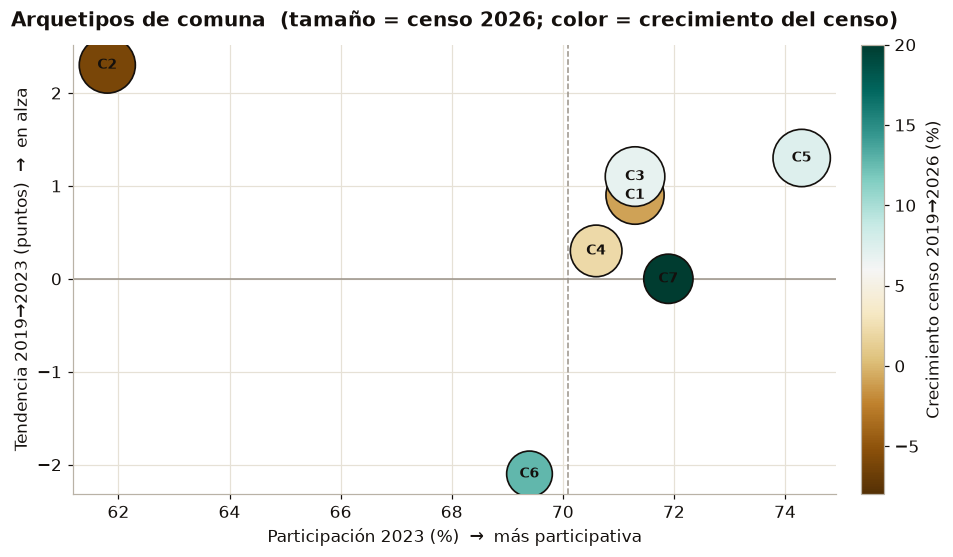

,part_2023,tendencia_19_23,censo_2026,crec_censo_19_26_%
territorio,,,,
COMUNA 1,71.3,0.9,27890,-1.0
COMUNA 2,61.8,2.3,25773,-6.1
COMUNA 3,71.3,1.1,29369,6.8
COMUNA 4,70.6,0.3,21430,2.1
COMUNA 5,74.3,1.3,27015,7.5
COMUNA 6,69.4,-2.1,16255,12.7
COMUNA 7,71.9,-0.0,19309,33.6


In [6]:
# Censo por comuna 2019 / 2023 / 2026
cen = pd.DataFrame({
    "censo_2019": at[(at.anio==2019)&(at.corporacion=="ALCALDE")].set_index("territorio").potencial_electoral,
    "censo_2023": at[(at.anio==2023)&(at.corporacion=="ALCALDE")].set_index("territorio").potencial_electoral,
}).reindex(URB)
dv1 = pd.read_csv(R26/"presidencia_2026_1v_divipol_barrancabermeja.csv", dtype=str)
cen["censo_2026"] = ((pd.to_numeric(dv1.potencial_hombres,errors="coerce").fillna(0)
                    + pd.to_numeric(dv1.potencial_mujeres,errors="coerce").fillna(0))
                     .groupby(dv1.comuna_divipol).sum().reindex(URB))
cen = cen.astype(float)

p23 = part(2023,"ALCALDE"); p19 = part(2019,"ALCALDE")
seg = pd.DataFrame({
    "part_2023": p23.round(1),
    "tendencia_19_23": (p23 - p19).round(1),
    "censo_2026": cen.censo_2026.astype(int),
    "crec_censo_19_26_%": ((cen.censo_2026/cen.censo_2019 - 1)*100).round(1),
})

fig, ax = plt.subplots(figsize=(8.8, 5.2))
sizes = (seg.censo_2026/seg.censo_2026.max()*1400)+120
sc = ax.scatter(seg.part_2023, seg.tendencia_19_23, s=sizes,
                c=seg["crec_censo_19_26_%"], cmap="BrBG", vmin=-8, vmax=20,
                edgecolor=INK, linewidth=1.1, zorder=3)
ax.axhline(0, color=MUTED, lw=1); ax.axvline(seg.part_2023.mean(), color=MUTED, lw=1, ls="--")
for c in URB:
    ax.annotate(c.replace("COMUNA ","C"), (seg.part_2023[c], seg.tendencia_19_23[c]),
                ha="center", va="center", fontsize=9, fontweight="bold", zorder=4)
ax.set_xlabel("Participación 2023 (%)  →  más participativa")
ax.set_ylabel("Tendencia 2019→2023 (puntos)  →  en alza")
ax.set_title("Arquetipos de comuna  (tamaño = censo 2026; color = crecimiento del censo)")
cb = fig.colorbar(sc, ax=ax, fraction=.045, pad=.03); cb.set_label("Crecimiento censo 2019→2026 (%)")
plt.tight_layout(); plt.show()
display(seg)


**Hallazgo 4 — Cuatro perfiles distintos, cuatro estrategias distintas.** `Nivel B`

- **Comuna 2 — grande, apática y encogiéndose:** la de menor participación y censo a la baja. Gran bolsa de voto dormido, pero difícil de activar.
- **Comunas 6 y 7 — la periferia que crece:** censo disparado (C7 **+25 %** 2019→2023), participación alta; es donde se está moviendo el electorado.
- **Comuna 5 — el bastión participativo:** la de mayor participación y en alza.
- **Comunas 1, 3, 4 — el centro estable:** participación ~70 %, poco movimiento.

*Lo que NO significa:* los arquetipos son descriptivos, no categorías fijas; una comuna puede cambiar de perfil si cambian censo o movilización.


## 6. El censo se mueve: a dónde va el electorado y con qué edades

El censo electoral no es estático. Ver cómo se redistribuye entre comunas —y qué edad tiene cada una— es clave para 2027.


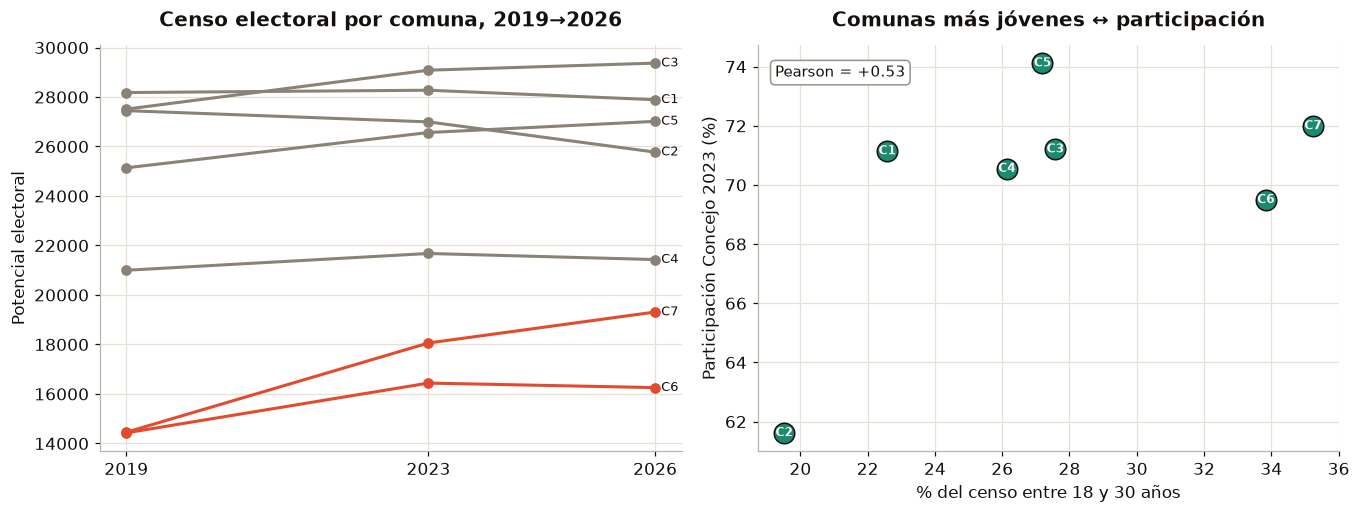

Crecimiento del censo 2019→2026 por comuna:
territorio
COMUNA 7    33.6
COMUNA 6    12.7
COMUNA 5     7.5
COMUNA 3     6.8
COMUNA 4     2.1
COMUNA 1    -1.0
COMUNA 2    -6.1

Censo urbano:  2019=158,148  2023=167,087  2026=167,041


In [7]:
# Evolución del censo por comuna + participación actual del censo
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

ax = axes[0]
yrs = [2019, 2023, 2026]
for c in URB:
    vals = [cen.loc[c, f"censo_{y}"] for y in yrs]
    ax.plot(yrs, vals, marker="o", lw=2,
            color=VERM if c in ("COMUNA 7","COMUNA 6") else ("#C7392020" if False else "#8A8276"),
            label=c if c in ("COMUNA 7","COMUNA 6","COMUNA 2") else None, zorder=3 if c in ("COMUNA 7","COMUNA 6","COMUNA 2") else 2)
    ax.annotate(c.replace("COMUNA ","C"), (2026, cen.loc[c,"censo_2026"]), fontsize=8.5, va="center",
                xytext=(4,0), textcoords="offset points")
ax.set_title("Censo electoral por comuna, 2019→2026"); ax.set_ylabel("Potencial electoral")
ax.set_xticks(yrs)

ax = axes[1]
pe = pd.read_csv(PROC/"participacion"/"perfil_etario_concejo_2023.csv")
pp = pd.read_csv(ANAL/"panel_puestos.csv", dtype=str)
mapc = pp[pp.anio=="2023"][["cod_zona","cod_puesto","territorio"]].drop_duplicates()
pe["cod_zona"] = pe["cod_zona"].astype(str).str.zfill(2); pe["cod_puesto"] = pe["cod_puesto"].astype(str).str.zfill(2)
pe = pe.merge(mapc, on=["cod_zona","cod_puesto"], how="left")
age = (pe[pe.territorio.isin(URB)].groupby("territorio")
       .apply(lambda d: pd.Series({
           "part": np.average(d.participacion, weights=d.potencial_electoral),
           "jovenes_18_30": np.average(d.pct_censo_18_a_30, weights=d.potencial_electoral)}))
       .reindex(URB))
ax.scatter(age.jovenes_18_30, age.part, s=180, color=TEAL, edgecolor=INK, zorder=3)
for c in URB:
    ax.annotate(c.replace("COMUNA ","C"), (age.jovenes_18_30[c], age.part[c]),
                ha="center", va="center", fontsize=8, color="white", fontweight="bold", zorder=4)
ax.set_xlabel("% del censo entre 18 y 30 años"); ax.set_ylabel("Participación Concejo 2023 (%)")
ax.set_title("Comunas más jóvenes ↔ participación")
if HAVE_SCIPY:
    r = pearsonr(age.jovenes_18_30, age.part).statistic
    ax.text(.03, .95, f"Pearson = {r:+.2f}", transform=ax.transAxes, fontsize=10, va="top",
            bbox=dict(boxstyle="round", fc="white", ec=MUTED))
plt.tight_layout(); plt.show()

print("Crecimiento del censo 2019→2026 por comuna:")
print(((cen.censo_2026/cen.censo_2019-1)*100).round(1).sort_values(ascending=False).to_string())
print(f"\nCenso urbano:  2019={int(cen.censo_2019.sum()):,}  2023={int(cen.censo_2023.sum()):,}  2026={int(cen.censo_2026.sum()):,}")


**Hallazgo 5 — El electorado se corre hacia la periferia joven.** `Nivel A/B`

El censo urbano total está casi **estancado** (~167 mil), pero por dentro se redistribuye: las **Comunas 6 y 7** (periferia) ganan electores y son las **más jóvenes** (33–35 % de su censo tiene 18–30 años), mientras la **Comuna 2 se encoge** y envejece. A nivel de comuna, las más jóvenes tienden a participar **más** (correlación positiva), al revés del tópico nacional.

*Lo que NO significa:* es una correlación **ecológica** entre territorios; no prueba que "los jóvenes votan más" a nivel individual. El dato etario es del **censo**, no de quienes efectivamente votaron.


## 7. Lo que esconden los datos

Hasta aquí, patrones de participación. Pero bajando al nivel de **mesa** —302.979 registros, cada partido y cada candidato en cada puesto— aparecen tres cosas que los promedios tapan.


### 7.1 El voto al Concejo es personal, no ideológico

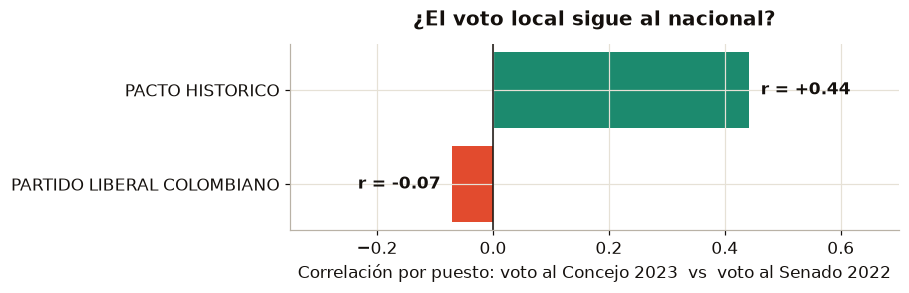

,partido,votos_concejo,votos_senado,r_puesto,n_puestos
0,PARTIDO LIBERAL COLOMBIANO,10024,10158,-0.070,53
1,PACTO HISTORICO,4111,22842,0.442,53


In [8]:
# Nacionalización: ¿la geografía del voto local sigue a la del nacional?
# (correlación por puesto del % de un mismo partido en Concejo 2023 vs Senado 2022)
nac = pd.read_csv(PROC/"analisis"/"nacionalizacion_concejo_2023_vs_senado_2022.csv")
fig, ax = plt.subplots(figsize=(8.4, 2.8))
colors = [VERM if r < 0.2 else TEAL for r in nac.r_puesto]
ax.barh(nac.partido, nac.r_puesto, color=colors)
ax.axvline(0, color=INK, lw=1)
for y, r in enumerate(nac.r_puesto):
    ax.text(r + (0.02 if r >= 0 else -0.02), y, f"r = {r:+.2f}", va="center",
            ha="left" if r >= 0 else "right", fontweight="bold")
ax.set_xlim(-0.35, 0.7)
ax.set_xlabel("Correlación por puesto: voto al Concejo 2023  vs  voto al Senado 2022")
ax.set_title("¿El voto local sigue al nacional?")
plt.tight_layout(); plt.show()
display(nac)


**Hallazgo 6 — El voto al Concejo no es un voto de partido; es un voto a la persona.** `Nivel B`

De todas las listas al Concejo, **solo dos** fuerzas con volumen compiten también al Senado — y ya eso dice mucho. El **Partido Liberal** (el tradicional) tiene correlación **−0,07** entre dónde saca votos para Concejo y dónde los saca para Senado: **cero relación**. Donde el liberalismo es fuerte para Senado, no lo es para Concejo. Su voto local no viaja con la marca del partido: viaja con el candidato. En cambio el **Pacto Histórico** (movimiento ideológico) sí alinea sus dos geografías (**+0,44**).

Traducción: en Barranca, el Concejo se gana con **nombre y red propia**, no con ideología ni con el partido. Por eso la mayoría del voto va a listas puramente locales que ni existen en lo nacional.

*Lo que NO significa:* no mide clientelismo directamente; mide que la geografía local y nacional de un mismo partido no coincide. Con solo dos partidos comparables, el contraste es ilustrativo.


### 7.2 Hay concejales elegidos por un solo puesto: los "fortines" 

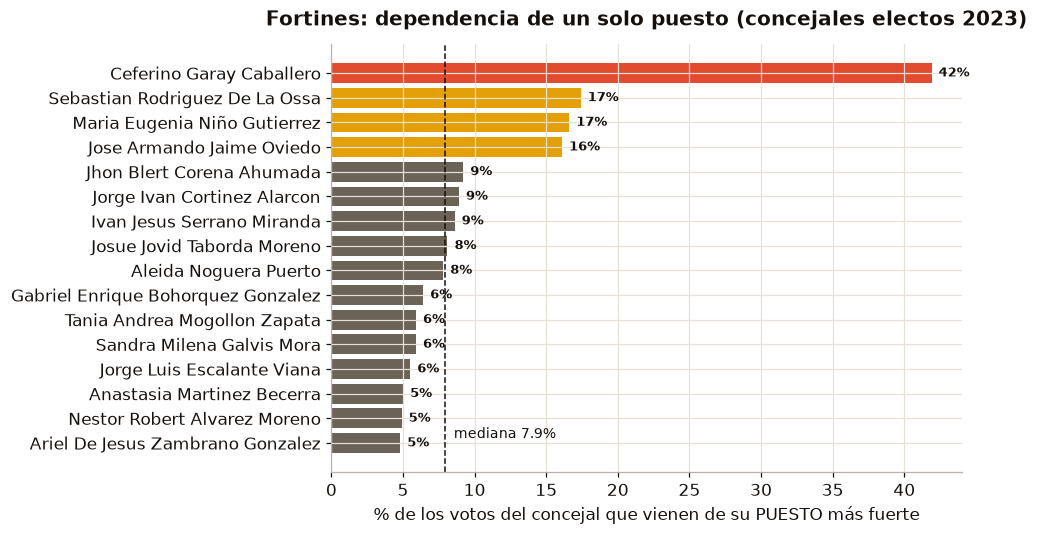

Outlier: Ceferino Garay Caballero — 42% de sus 1,684 votos en UN puesto
         (LA FORTUNA AUTOPISTA, CORREGIMIENTO LA FORTUNA AUTOPISTA); HHI=0.213 vs mediana 0.029


In [9]:
# Fortines: ¿cuánto del voto de cada concejal electo viene de un solo puesto?
fo = pd.read_csv(PROC/"analisis"/"fortines_concejo_2023.csv")
el = fo[fo.electo].sort_values("top_pto_pct", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
colors = [VERM if v > 30 else (OCHRE if v > 15 else "#6B6358") for v in el.top_pto_pct]
ax.barh([c.title() for c in el.candidato], el.top_pto_pct, color=colors)
med = el.top_pto_pct.median()
ax.axvline(med, color=INK, ls="--", lw=1); ax.text(med + 0.6, 0.2, f"mediana {med:.1f}%", fontsize=9)
for y, v in enumerate(el.top_pto_pct):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=8.5, fontweight="bold")
ax.set_xlabel("% de los votos del concejal que vienen de su PUESTO más fuerte")
ax.set_title("Fortines: dependencia de un solo puesto (concejales electos 2023)")
plt.tight_layout(); plt.show()
t = el.sort_values("top_pto_pct", ascending=False).iloc[0]
print(f"Outlier: {t.candidato.title()} — {t.top_pto_pct:.0f}% de sus {int(t.votos):,} votos en UN puesto")
print(f"         ({t.lugar_top}, {t.comuna_top}); HHI={t.hhi} vs mediana {el.hhi.median():.3f}")


**Hallazgo 7 — Un concejal fue elegido, esencialmente, por un solo puesto de votación.** `Nivel A/B`

**Ceferino Garay** sacó el **42 % de todos sus votos en un único puesto** (La Fortuna Autopista, zona rural), y dos de cada tres en apenas tres puestos. Su concentración (HHI 0,213) es **siete veces** la mediana de los electos (0,029): el caso extremo de **voto-fortín**, una base territorial capturada. En el otro extremo, concejales como Ariel Zambrano o Néstor Álvarez reparten su voto por toda la ciudad (≤5 % en su mejor puesto): votación transversal.

*Lo que NO significa:* alta concentración no prueba compra de votos ni irregularidad; mide **dependencia territorial**. Pero separa con nitidez dos formas de hacer política: tejer un bastión o sumar ciudad.


### 7.3 Dos abstenciones distintas: apatía vs. movilización solo local

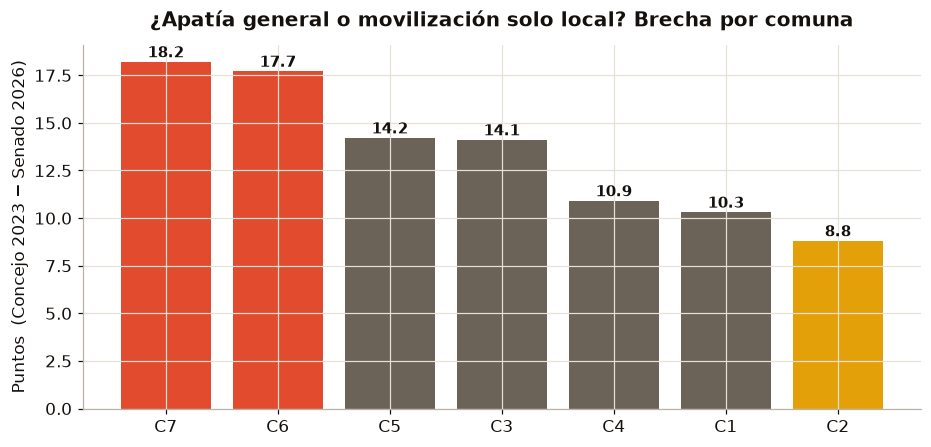

,Concejo_2023,Senado_2026,brecha
territorio,,,
COMUNA 7,72.0,53.8,18.2
COMUNA 6,69.5,51.8,17.7
COMUNA 5,74.1,59.9,14.2
COMUNA 3,71.2,57.1,14.1
COMUNA 4,70.6,59.7,10.9
COMUNA 1,71.1,60.9,10.3
COMUNA 2,61.6,52.9,8.8


In [10]:
# Brecha de movilización local - nacional por comuna
con23 = part(2023, "CONCEJO")
cong26 = pd.read_csv(PROC/"participacion"/"participacion_congreso_2026.csv")
sen26 = cong26.query("nivel=='comuna' & corporacion=='SENADO'").set_index("territorio").participacion.reindex(URB)
gap = (con23 - sen26).round(1).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.6, 4.2))
colors = [VERM if g > 15 else ("#6B6358" if g > 10 else OCHRE) for g in gap]
ax.bar([c.replace("COMUNA ", "C") for c in gap.index], gap.values, color=colors)
for i, g in enumerate(gap.values): ax.text(i, g + 0.25, f"{g:.1f}", ha="center", fontweight="bold", fontsize=9.5)
ax.set_ylabel("Puntos  (Concejo 2023 − Senado 2026)")
ax.set_title("¿Apatía general o movilización solo local? Brecha por comuna")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Concejo_2023": con23.round(1), "Senado_2026": sen26.round(1),
                     "brecha": (con23 - sen26).round(1)}).reindex(gap.index))


**Hallazgo 8 — La abstención de la Comuna 2 no es la misma que la de las Comunas 6 y 7.** `Nivel B`

El promedio esconde que hay **dos abstenciones distintas**:
- **Comunas 6 y 7** (periferia en crecimiento): votan ~70 % en lo local pero caen a ~52 % en lo nacional — **brecha de ~18 puntos**. Su electorado se **activa sobre todo para lo local**: firma de movilización local intensa.
- **Comuna 2**: su brecha es la **menor (~9 pts)**. No se activa para lo local; participa poco **en todo** por igual — apatía pareja.

Y aquí se cierra el círculo con el censo: las comunas que **más crecen** (6 y 7) son las que **más se activan justo para las territoriales**. Ahí se está concentrando el voto que decide una elección local.

*Lo que NO significa:* "movilización local" describe el patrón; no identifica su causa (arraigo comunitario, liderazgos locales u otras redes).


## 8. Anatomía de una lista: qué combinaciones producen curul

Esta es la sección central del cuaderno. La pregunta: juntando **los dos ciclos territoriales** (2019 y 2023), ¿qué estructura de candidatos produce una curul y cuál no?

### 8.0 Aclaración previa: qué hay que explicar y qué no

Conviene separar dos cosas que suelen confundirse.

**Lo que NO es un hallazgo.** Si una lista saca curul está determinado por la ley (Art. 263 CP): se ordenan los cocientes `votos/1…17`, el 17.º fija la **cifra repartidora**, y cada lista obtiene `total ÷ cifra` curules. Verificado abajo, la regla *"total ≥ cifra"* clasifica correctamente **17/17 listas en 2019 y 23/23 en 2023**. Eso no es un descubrimiento: es aritmética electoral. Decir "las listas ganadoras tienen más votos" sería una tautología disfrazada de análisis.

**Lo que SÍ hay que explicar.** La pregunta con contenido empírico es la **función de producción**: qué combinación de candidatos genera ese total. Dos listas pueden llegar a 6.000 votos con estructuras opuestas —una con 4 figuras, otra con 20 campañas medianas— y de eso dependen tanto el total alcanzable como quién se queda con la curul. Esa es la pregunta que se responde aquí.

### 8.0.1 Regla de rigor para esta sección

Con solo 43 listas en dos ciclos, es fácil encontrar "patrones" que son ruido. En esta sección se aplican tres reglas, y se dejan ver los casos en que fallan:

1. **Todo patrón se reporta por periodo, nunca agregado.** Si una regla no se cumple en 2019 **y** en 2023, se marca como **no replicada** y no se usa como recomendación.
2. **Se declara siempre el `n` de cada celda.** Una celda con n=1 o n=2 es ilustrativa, no una regla.
3. **El umbral de "fuerte" se prueba con dos definiciones** (absoluta y relativa a la cifra de cada año). Un patrón que cambia según la definición no es robusto.


### 8.1 ¿Dónde está el piso real de un concejal? Validación por periodo

Antes de clasificar candidatos hay que fijar el umbral de "fuerte" con el dato, no por conveniencia.


In [11]:
# --- Piso empírico del concejal electo, calculado en cada ciclo por separado ---
ce = pd.read_csv(ANAL/"candidato_eleccion.csv", encoding="utf-8-sig")
pe = pd.read_csv(ANAL/"partido_eleccion.csv",   encoding="utf-8-sig")
ce = ce[ce.corporacion=="CONCEJO"].copy(); pe = pe[pe.corporacion=="CONCEJO"].copy()

def seats_cifra(year):
    "Cifra repartidora (Art. 263 CP) y curules por lista."
    t  = pe[pe.anio==year].set_index("nombre_partido")["votos"]
    qs = sorted([(v/i, p) for p, v in t.items() for i in range(1,18)], key=lambda x:-x[0])[:17]
    s  = {p:0 for p in t.index}
    for q, p in qs: s[p] += 1
    return s, qs[-1][0]

CIF = {y: seats_cifra(y)[1] for y in (2019, 2023)}

filas = []
for year in (2019, 2023):
    s, cif = seats_cifra(year)
    electos, perdieron = [], []
    for part, d in ce[ce.anio==year].groupby("nombre_partido"):
        pr = pe[(pe.anio==year) & (pe.nombre_partido==part)]
        if len(pr) and bool(pr["sin_voto_preferente_observado"].iloc[0]):
            continue                       # lista cerrada: no hay voto preferente que ordenar
        dd = d.sort_values("votos", ascending=False).reset_index(drop=True)
        cur = s.get(part, 0)
        for rk, r in dd.iterrows():
            (electos if rk < cur else perdieron).append((r.nombre_candidato, int(r.votos)))
    ve = [v for _, v in electos]
    filas.append(dict(anio=year, cifra=round(cif), n_electos=len(ve),
                      piso=min(ve), mediana=int(np.median(ve)),
                      piso_pct_cifra=round(100*min(ve)/cif, 1),
                      mejor_no_electo=max(v for _, v in perdieron)))
PISOS = pd.DataFrame(filas)
display(PISOS)

print("El piso del electo escala con la cifra repartidora:")
for _, r in PISOS.iterrows():
    print(f"  {int(r.anio)}: piso {r.piso:,} votos = {r.piso_pct_cifra}% de la cifra ({int(r.cifra):,})")
print("\nDos definiciones de FUERTE que se usarán en paralelo:")
print(f"  (a) absoluta  : >= 930 votos en ambos años")
print(f"  (b) relativa  : >= 23% de la cifra del año  ->  2019: {0.23*CIF[2019]:.0f}   2023: {0.23*CIF[2023]:.0f}")


,anio,cifra,n_electos,piso,mediana,piso_pct_cifra,mejor_no_electo
0,2019,4412,17,1013,1701,23.0,1705
1,2023,4042,16,932,1519,23.1,1472


El piso del electo escala con la cifra repartidora:
  2019: piso 1,013.0 votos = 23.0% de la cifra (4,412)
  2023: piso 932.0 votos = 23.1% de la cifra (4,042)

Dos definiciones de FUERTE que se usarán en paralelo:
  (a) absoluta  : >= 930 votos en ambos años
  (b) relativa  : >= 23% de la cifra del año  ->  2019: 1015   2023: 930


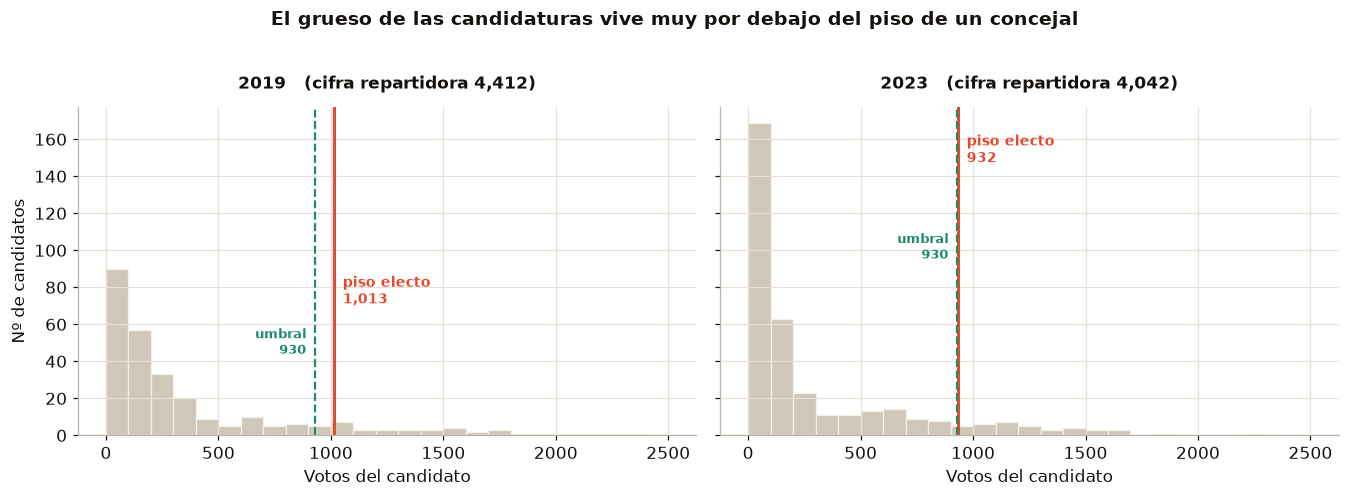

In [12]:
# Gráfico: distribución del voto por candidato y dónde cae el piso del electo
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.4), sharey=True)
for ax, year in zip(axes, (2019, 2023)):
    v    = ce[ce.anio==year].votos.values
    piso = int(PISOS.loc[PISOS.anio==year, "piso"].iloc[0])
    cif  = CIF[year]
    ax.hist(v, bins=np.arange(0, 2600, 100), color="#CFC8BA", edgecolor=PAPER, linewidth=.8)
    ax.axvline(piso, color=VERM, lw=2)
    ax.axvline(930,  color=TEAL, lw=1.4, ls="--")
    ax.text(piso+40, ax.get_ylim()[1]*.92, f"piso electo\n{piso:,}", color=VERM,
            fontsize=9, fontweight="bold", va="top")
    ax.text(930-40, ax.get_ylim()[1]*.62, "umbral\n930", color=TEAL, fontsize=8.5,
            fontweight="bold", va="top", ha="right")
    ax.set_title(f"{year}   (cifra repartidora {cif:,.0f})", fontsize=11)
    ax.set_xlabel("Votos del candidato")
axes[0].set_ylabel("Nº de candidatos")
fig.suptitle("El grueso de las candidaturas vive muy por debajo del piso de un concejal",
             fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()


**Hallazgo 9 — El piso del concejal no es un número fijo: es una fracción estable de la cifra repartidora.** `Nivel A/B`

El concejal menos votado sacó **1.013 votos en 2019** y **932 en 2023**. En bruto parecen distintos, pero medidos contra la cifra repartidora de su año son **23,0 %** y **23,1 %** — prácticamente idénticos. El piso no bajó: bajó la cifra (de 4.412 a 4.042), y el piso la siguió.

Esto importa para 2027: el umbral de entrada no es "930 votos", es **≈23 % de la cifra que resulte ese año**. Si la participación sube, el piso sube con ella.

*Lo que NO significa:* son **dos** observaciones. Que coincidan en 23 % es notable, pero no demuestra una constante; es una regularidad a vigilar, no una ley.


### 8.2 La matriz: fuertes × medios, celda por celda y año por año

Clasificamos cada lista por dos números: cuántos **fuertes** (★, ≥930) y cuántos **medios** (M, 500–929) lleva. Esto cubre todas las combinaciones posibles sin huecos.

Cada celda muestra los dos años por separado, precisamente para ver si el patrón **se repite** o si ocurrió una sola vez.


In [13]:
# --- Anatomía de cada lista, con las dos definiciones de umbral ---
PISO_REL = {y: 0.23*CIF[y] for y in (2019, 2023)}

filas = []
for year in (2019, 2023):
    s, cif = seats_cifra(year)
    # Se recorre el censo de LISTAS (no de candidatos): así las listas cerradas,
    # que no tienen candidatos con voto preferente, quedan contadas y se excluyen
    # de forma explícita en vez de desaparecer en silencio.
    for _, pr_row in pe[pe.anio==year].iterrows():
        part = pr_row.nombre_partido
        d    = ce[(ce.anio==year) & (ce.nombre_partido==part)]
        v    = np.sort(d.votos.values)[::-1] if len(d) else np.array([], dtype=int)
        pr   = pe[(pe.anio==year) & (pe.nombre_partido==part)]
        tot     = int(pr_row["votos"])
        cerrada = bool(pr_row["sin_voto_preferente_observado"])
        prel    = PISO_REL[year]
        filas.append(dict(
            anio=year, lista=part, cifra=round(cif), curules=s.get(part,0),
            total=tot, cerrada=cerrada,
            F=int((v>=930).sum()),  M=int(((v>=500)&(v<930)).sum()),
            F_rel=int((v>=prel).sum()), M_rel=int(((v>=0.124*cif)&(v<prel)).sum()),
            S=int(((v>=300)&(v<500)).sum()), c=int(((v>=100)&(v<300)).sum()),
            r=int(((v>=50)&(v<100)).sum()),  f=int((v<50).sum()),
            top1=int(v[0]) if len(v) else 0,
            top1_sh=round(100*v[0]/tot,1) if tot and len(v) else 0))
LA = pd.DataFrame(filas)
LA["gano"]  = LA.curules >= 1
LA["banca"] = LA.M + LA.S + LA.c          # candidaturas entre 100 y 929 votos
LA["quemados"] = (LA.F - LA.curules).clip(lower=0)
AB = LA[~LA.cerrada].copy()               # listas abiertas (con voto preferente)

print(f"Listas analizadas: {len(LA)}  ({len(AB)} abiertas + {int(LA.cerrada.sum())} cerradas)")
print("Las listas CERRADAS se excluyen de la matriz: no tienen voto preferente,")
print("así que no se les puede contar fuertes ni medios.\n")

print("REGLA LEGAL (no es un hallazgo) — 'total >= cifra' clasifica:")
for y in (2019, 2023):
    s = LA[LA.anio==y]
    ok = ((s.total >= s.cifra) == s.gano).sum()
    print(f"   {y}: {ok}/{len(s)} listas correctamente  ({100*ok/len(s):.0f}%)")


Listas analizadas: 43  (40 abiertas + 3 cerradas)
Las listas CERRADAS se excluyen de la matriz: no tienen voto preferente,
así que no se les puede contar fuertes ni medios.

REGLA LEGAL (no es un hallazgo) — 'total >= cifra' clasifica:
   2019: 18/18 listas correctamente  (100%)
   2023: 25/25 listas correctamente  (100%)


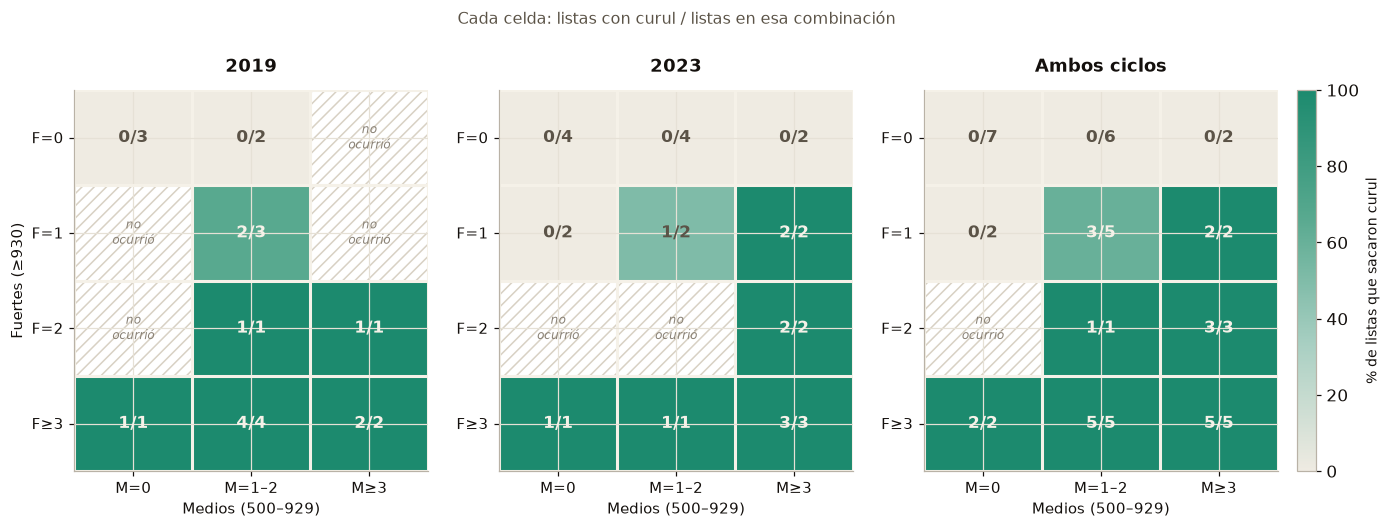

In [14]:
# --- Matriz F x M, un panel por año + panel combinado ---
Fb = [(0,0,"F=0"), (1,1,"F=1"), (2,2,"F=2"), (3,99,"F≥3")]
Mb = [(0,0,"M=0"), (1,2,"M=1–2"), (3,99,"M≥3")]

def celda(df, flo, fhi, mlo, mhi):
    s = df[(df.F>=flo)&(df.F<=fhi)&(df.M>=mlo)&(df.M<=mhi)]
    return len(s), int(s.gano.sum())

paneles = [("2019", AB[AB.anio==2019]), ("2023", AB[AB.anio==2023]), ("Ambos ciclos", AB)]
fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.5))

for ax, (titulo, df) in zip(axes, paneles):
    tasa = np.full((len(Fb), len(Mb)), np.nan)
    txt  = [["" for _ in Mb] for _ in Fb]
    for i, (flo, fhi, _) in enumerate(Fb):
        for j, (mlo, mhi, _) in enumerate(Mb):
            n, w = celda(df, flo, fhi, mlo, mhi)
            if n:
                tasa[i, j] = 100*w/n
                txt[i][j]  = f"{w}/{n}"
            else:
                txt[i][j] = "no\nocurrió"
    # rampa secuencial de un solo tono (gris claro -> teal), magnitud = tasa de éxito
    cmap = LinearSegmentedColormap.from_list("t", ["#EFEBE2", "#A8CFC2", "#58A98F", TEAL])
    im = ax.imshow(tasa, cmap=cmap, vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(Mb))); ax.set_xticklabels([l for *_, l in Mb], fontsize=9.5)
    ax.set_yticks(range(len(Fb))); ax.set_yticklabels([l for *_, l in Fb], fontsize=9.5)
    for i in range(len(Fb)):
        for j in range(len(Mb)):
            val = tasa[i, j]
            vacia = np.isnan(val)
            if vacia:                                   # celda sin casos: rayada y rotulada
                ax.add_patch(plt.Rectangle((j-.5, i-.5), 1, 1, facecolor="#FFFFFF",
                                           hatch="///", edgecolor="#D8D1C4", linewidth=0))
            col = PAPER if (not vacia and val >= 55) else "#8A8276" if vacia else "#5B5347"
            ax.text(j, i, txt[i][j], ha="center", va="center", color=col,
                    fontsize=8 if vacia else 11,
                    fontweight="normal" if vacia else "bold",
                    style="italic" if vacia else "normal")
    ax.set_title(titulo, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Medios (500–929)", fontsize=9.5)
    if ax is axes[0]: ax.set_ylabel("Fuertes (≥930)", fontsize=9.5)
    ax.set_xticks(np.arange(-.5, len(Mb), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(Fb), 1), minor=True)
    ax.grid(which="minor", color=PAPER, linewidth=2); ax.tick_params(which="minor", length=0)

cb = fig.colorbar(im, ax=axes, fraction=.018, pad=.015)
cb.set_label("% de listas que sacaron curul", fontsize=9)
fig.suptitle("Cada celda: listas con curul / listas en esa combinación",
             fontsize=10.5, y=1.04, color="#5B5347")
plt.show()


In [15]:
# --- ¿Qué celdas replican en los dos ciclos? ---
print(f"{'celda':12} | {'2019':>8} | {'2023':>8} | veredicto")
print("-"*58)
for flo, fhi, fl in Fb:
    for mlo, mhi, ml in Mb:
        n19, w19 = celda(AB[AB.anio==2019], flo, fhi, mlo, mhi)
        n23, w23 = celda(AB[AB.anio==2023], flo, fhi, mlo, mhi)
        if n19 + n23 == 0: continue
        s19 = f"{w19}/{n19}" if n19 else "—"
        s23 = f"{w23}/{n23}" if n23 else "—"
        if n19 and n23:
            ver = "replica" if (w19/n19 > .5) == (w23/n23 > .5) else "NO REPLICA"
        else:
            ver = "solo 1 ciclo (no verificable)"
        print(f"{fl+' '+ml:12} | {s19:>8} | {s23:>8} | {ver}")

print("\n" + "="*58)
print("LAS TRES FRANJAS, validadas en cada ciclo por separado")
print("="*58)
for etiqueta, mask in [("F=0  nunca saca curul",  AB.F==0),
                       ("F=1  zona de riesgo",    AB.F==1),
                       ("F≥2  siempre sacó curul", AB.F>=2)]:
    a = AB[mask & (AB.anio==2019)]; b = AB[mask & (AB.anio==2023)]
    t = AB[mask]
    print(f"  {etiqueta:24}  2019: {int(a.gano.sum())}/{len(a)}    "
          f"2023: {int(b.gano.sum())}/{len(b)}    total: {int(t.gano.sum())}/{len(t)}")

# Robustez: ¿aguanta con el umbral relativo a la cifra de cada año?
print("\nRobustez con umbral RELATIVO (23% de la cifra del año):")
for etiqueta, mask in [("F=0", AB.F_rel==0), ("F=1", AB.F_rel==1), ("F≥2", AB.F_rel>=2)]:
    a = AB[mask & (AB.anio==2019)]; b = AB[mask & (AB.anio==2023)]
    print(f"  {etiqueta:4}  2019: {int(a.gano.sum())}/{len(a)}    2023: {int(b.gano.sum())}/{len(b)}")


celda        |     2019 |     2023 | veredicto
----------------------------------------------------------
F=0 M=0      |      0/3 |      0/4 | replica
F=0 M=1–2    |      0/2 |      0/4 | replica
F=0 M≥3      |        — |      0/2 | solo 1 ciclo (no verificable)
F=1 M=0      |        — |      0/2 | solo 1 ciclo (no verificable)
F=1 M=1–2    |      2/3 |      1/2 | NO REPLICA
F=1 M≥3      |        — |      2/2 | solo 1 ciclo (no verificable)
F=2 M=1–2    |      1/1 |        — | solo 1 ciclo (no verificable)
F=2 M≥3      |      1/1 |      2/2 | replica
F≥3 M=0      |      1/1 |      1/1 | replica
F≥3 M=1–2    |      4/4 |      1/1 | replica
F≥3 M≥3      |      2/2 |      3/3 | replica

LAS TRES FRANJAS, validadas en cada ciclo por separado
  F=0  nunca saca curul     2019: 0/5    2023: 0/10    total: 0/15
  F=1  zona de riesgo       2019: 2/3    2023: 3/6    total: 5/9
  F≥2  siempre sacó curul   2019: 9/9    2023: 7/7    total: 16/16

Robustez con umbral RELATIVO (23% de la cifra del añ

**Hallazgo 10 — Tres franjas, y solo dos de ellas son reglas.** `Nivel B`

Leyendo la matriz por franjas de fuertes, y verificando **cada ciclo por separado**:

| Franja | 2019 | 2023 | Total | ¿Replica? |
|---|:---:|:---:|:---:|:---:|
| **F = 0** — ninguna figura ≥930 | 0/5 | 0/10 | **0/15** | **Sí** |
| **F = 1** — una sola figura | 2/3 | 3/6 | 5/9 | zona mixta |
| **F ≥ 2** — dos o más figuras | 9/9 | 7/7 | **16/16** | **Sí** |

Dos reglas sobreviven la prueba de replicación, y se mantienen además con el umbral relativo:

- **Sin ninguna figura que llegue al piso, una lista abierta nunca sacó curul.** 15 listas, dos ciclos, cero excepciones. El ancla es condición necesaria.
- **Con dos o más figuras, siempre sacó curul.** 16 listas, dos ciclos, cero excepciones.

La franja intermedia (una sola figura) es **genuinamente indeterminada**: se decide por otra variable, que es lo que mira la sección siguiente.

*Lo que NO significa:* "F≥2 ⇒ curul" describe 16 casos observados; no es una garantía mecánica. Una lista con 2 fuertes de 940 votos cada uno y nada más sumaría ~2.000 y no alcanzaría. Que no haya ocurrido refleja que quien atrae dos figuras suele atraer también banca — es una correlación estructural, no una ley causal.

*Celdas no verificables:* F=0/M≥3, F=1/M=0, F=1/M≥3 y F=2/M=1–2 aparecen en **un solo ciclo**. Se muestran, pero no sustentan ninguna recomendación.


### 8.3 La zona de riesgo: con una sola figura, decide la banca

Nueve listas llevaron exactamente un fuerte. Cinco sacaron curul y cuatro no. ¿Qué las separa?


In [16]:
# --- Dentro de la franja F=1: ¿qué variable separa? ---
Z = AB[AB.F==1].sort_values("banca").reset_index(drop=True)
print("Listas con exactamente UN candidato fuerte, ordenadas por tamaño de banca")
print("(banca = candidaturas entre 100 y 929 votos)\n")
print(f"{'año':>5}  {'lista':38} {'banca':>6} {'total':>7} {'cifra':>7} {'curul':>6}")
print("-"*76)
for _, r in Z.iterrows():
    print(f"{int(r.anio):>5}  {r.lista[:38]:38} {int(r.banca):>6} {int(r.total):>7,} "
          f"{int(r.cifra):>7,} {int(r.curules):>6}")

lo = Z[~Z.gano].banca.max(); hi = Z[Z.gano].banca.min()
print(f"\nCorte: banca ≤ {int(lo)} → {int((~Z[Z.banca<=lo].gano).sum())}/{int((Z.banca<=lo).sum())} sin curul")
print(f"       banca ≥ {int(hi)} → {int(Z[Z.banca>=hi].gano.sum())}/{int((Z.banca>=hi).sum())} con curul")
print(f"Separación limpia, sin solapamiento, y presente en los dos ciclos:")
for y in (2019, 2023):
    zz = Z[Z.anio==y]
    g, p = zz[zz.gano], zz[~zz.gano]
    if len(g) and len(p):
        print(f"   {y}: con curul banca {sorted(g.banca.tolist())} | sin curul banca {sorted(p.banca.tolist())}")
    elif len(g):
        print(f"   {y}: con curul banca {sorted(g.banca.tolist())} | (sin perdedoras en esta franja)")


Listas con exactamente UN candidato fuerte, ordenadas por tamaño de banca
(banca = candidaturas entre 100 y 929 votos)

  año  lista                                   banca   total   cifra  curul
----------------------------------------------------------------------------
 2023  JUNTOS                                      4   3,096   4,042      0
 2023  VAMOS UNIDOS                                5   3,033   4,042      0
 2023  LOS VERIDICOS                               6   3,095   4,042      0
 2019  BARRANCABERMEJA LIBRE HUMANA Y EN PAZ       6   3,600   4,412      0
 2023  POR UN CAMBIO BUENO Y JUSTO                 7   4,073   4,042      1
 2023  PARTIDO POLÍTICO LA FUERZA DE LA PAZ        8   5,600   4,042      1
 2019  BIENESTAR Y UNIDAD SOCIAL - BUS             9   4,464   4,412      1
 2023  PARTIDO DEMÓCRATA COLOMBIANO               11   6,267   4,042      1
 2019  MOVIMIENTO SOCIAL TAREA DE TODOS           12   4,454   4,412      1

Corte: banca ≤ 6 → 4/4 sin curul
       ba

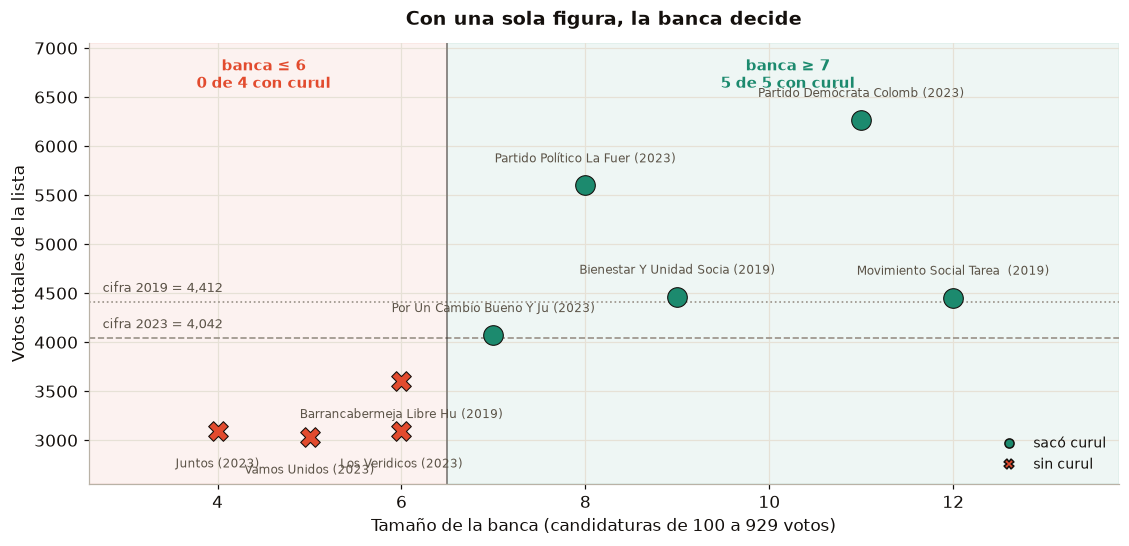

In [17]:
# Gráfico: el corte de la banca en la franja de una sola figura
fig, ax = plt.subplots(figsize=(10.4, 5.1))
ax.set_xlim(2.6, 13.8); ax.set_ylim(2550, 7050)
for y, ls in [(2019, ":"), (2023, "--")]:
    ax.axhline(CIF[y], color=MUTED, ls=ls, lw=1.1)
    ax.text(2.75, CIF[y]+70, f"cifra {y} = {CIF[y]:,.0f}", va="bottom",
            fontsize=8.2, color="#5B5347")
ax.axvspan(2.6, 6.5,  color=VERM, alpha=.07, zorder=0)
ax.axvspan(6.5, 13.8, color=TEAL, alpha=.07, zorder=0)
ax.axvline(6.5, color=INK, lw=1.2, alpha=.45)
for _, r in Z.iterrows():
    gano = bool(r.gano)
    ax.scatter(r.banca, r.total, s=165, zorder=3,
               color=TEAL if gano else VERM,
               marker="o" if gano else "X",            # forma además del color
               edgecolor=INK, linewidth=.7)
    # alterna arriba/abajo para que no se pisen las etiquetas del grupo bajo
    dy = 15 if gano else -24
    ax.annotate(f"{r.lista.title()[:24]} ({int(r.anio)})", (r.banca, r.total),
                xytext=(0, dy), textcoords="offset points",
                fontsize=7.8, ha="center", color="#5B5347")
ax.text(4.5, 6900, "banca ≤ 6\n0 de 4 con curul", ha="center", va="top",
        fontsize=9.5, fontweight="bold", color=VERM)
ax.text(10.2, 6900, "banca ≥ 7\n5 de 5 con curul", ha="center", va="top",
        fontsize=9.5, fontweight="bold", color=TEAL)
ax.set_xlabel("Tamaño de la banca (candidaturas de 100 a 929 votos)")
ax.set_ylabel("Votos totales de la lista")
ax.set_title("Con una sola figura, la banca decide", fontsize=12.5, fontweight="bold")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([],[],marker="o",ls="",color=TEAL,markeredgecolor=INK,label="sacó curul"),
                   Line2D([],[],marker="X",ls="",color=VERM,markeredgecolor=INK,label="sin curul")],
          frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()


**Hallazgo 11 — En la franja de una sola figura, la banca separa sin solapamiento.** `Nivel B`

Las nueve listas con exactamente un fuerte se ordenan perfectamente por el tamaño de su banca:

- **Banca de 4 a 6 candidaturas → 0 de 4 sacaron curul.**
- **Banca de 7 a 12 candidaturas → 5 de 5 sacaron curul.**

No hay un solo caso cruzado, y el corte aparece en ambos ciclos (2019: con curul 9 y 12, sin curul 6; 2023: con curul 7, 8 y 11, sin curul 4, 5 y 6).

Traducido: **una figura sola no levanta una lista.** Kelly Ortiz aportó 1.472 votos —el 48 % de su lista— y Vamos Unidos se quedó en 3.033 porque detrás había solo 5 candidaturas con más de 100 votos. Con esa misma figura y una banca de 9 o 10, la lista habría superado la cifra.

*Lo que NO significa:* son nueve listas. El corte en 7 es **el borde observado en esta muestra**, no un umbral calibrado; con más ciclos podría moverse a 6 u 8. Lo robusto es la dirección —más banca, más total—, no el número exacto. Y la banca no es mágica: opera porque cada candidatura de 100–929 votos aporta volumen real al total.


### 8.4 La tasa de cambio: cuánto aporta cada tipo de candidato

Si una curul cuesta ~4.000 votos, ¿cuántos candidatos de cada tipo hacen falta? Esta es la pregunta de ensamblaje, y su respuesta resulta ser **casi idéntica en los dos ciclos**.


In [18]:
# --- Voto medio por rango y equivalencia en curules, por ciclo ---
RANGOS = [("★ fuerte (≥930)", 930, 10**9), ("M medio (500–929)", 500, 930),
          ("S seria (300–499)", 300, 500),  ("c campaña (100–299)", 100, 300),
          ("r relleno (50–99)",  50, 100),  ("f fantasma (<50)",     0,  50)]

tab = []
for lbl, lo, hi in RANGOS:
    fila = {"rango": lbl}
    for y in (2019, 2023):
        s = ce[(ce.anio==y) & (ce.votos>=lo) & (ce.votos<hi)]
        fila[f"n_{y}"]     = len(s)
        fila[f"voto_{y}"]  = round(s.votos.mean()) if len(s) else 0
        fila[f"=1curul_{y}"] = round(CIF[y]/s.votos.mean(), 1) if len(s) and s.votos.mean() else np.nan
    tab.append(fila)
TC = pd.DataFrame(tab)
display(TC)

print("Cuántos candidatos de cada tipo equivalen a UNA curul:")
for _, r in TC.iterrows():
    if np.isnan(r["=1curul_2019"]): continue
    d = abs(r["=1curul_2019"] - r["=1curul_2023"])
    marca = "  <- estable" if d <= max(1.0, .12*r["=1curul_2019"]) else ""
    print(f"  {r['rango']:22} 2019: {r['=1curul_2019']:>5.1f}   2023: {r['=1curul_2023']:>5.1f}{marca}")


,rango,n_2019,voto_2019,=1curul_2019,n_2023,voto_2023,=1curul_2023
0,★ fuerte (≥930),38,1465,3.0,37,1302,3.1
1,M medio (500–929),28,712,6.2,45,675,6.0
2,S seria (300–499),29,379,11.6,22,385,10.5
3,c campaña (100–299),90,179,24.6,86,170,23.8
4,r relleno (50–99),42,69,64.4,78,70,57.7
5,f fantasma (<50),48,29,149.9,91,29,140.2


Cuántos candidatos de cada tipo equivalen a UNA curul:
  ★ fuerte (≥930)        2019:   3.0   2023:   3.1  <- estable
  M medio (500–929)      2019:   6.2   2023:   6.0  <- estable
  S seria (300–499)      2019:  11.6   2023:  10.5  <- estable
  c campaña (100–299)    2019:  24.6   2023:  23.8  <- estable
  r relleno (50–99)      2019:  64.4   2023:  57.7  <- estable
  f fantasma (<50)       2019: 149.9   2023: 140.2  <- estable


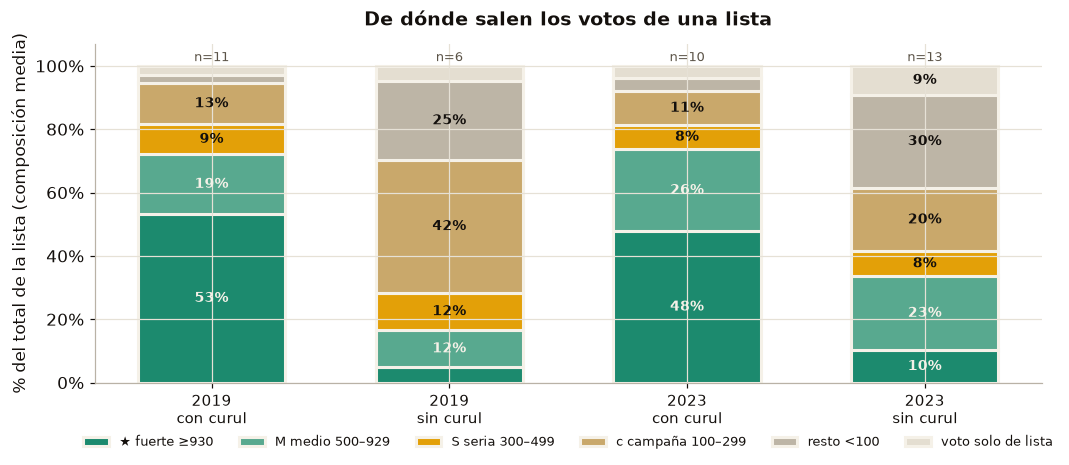

Mediana del % aportado por candidatos fuertes (≥930):
   2019 con curul    58.2 %   (n=11)
   2019 sin curul     0.0 %   (n=6)
   2023 con curul    43.0 %   (n=10)
   2023 sin curul     0.0 %   (n=13)


In [19]:
# --- De dónde salen los votos: aporte de cada rango, ganadoras vs perdedoras, por ciclo ---
recs = []
for _, L in AB.iterrows():
    v = ce[(ce.anio==L.anio) & (ce.nombre_partido==L.lista)].votos.values
    if L.total <= 0 or not len(v): continue
    recs.append(dict(anio=L.anio, gano=L.gano,
        F=100*v[v>=930].sum()/L.total,
        M=100*v[(v>=500)&(v<930)].sum()/L.total,
        S=100*v[(v>=300)&(v<500)].sum()/L.total,
        c=100*v[(v>=100)&(v<300)].sum()/L.total,
        resto=100*v[v<100].sum()/L.total,
        # votos al logo sin marcar candidato: no pertenecen a ningún rango
        solo_lista=100*(L.total - v.sum())/L.total))
AP = pd.DataFrame(recs)

fig, ax = plt.subplots(figsize=(10.2, 4.4))
grupos = [(2019, True), (2019, False), (2023, True), (2023, False)]
etiq   = ["2019\ncon curul", "2019\nsin curul", "2023\ncon curul", "2023\nsin curul"]
capas  = [("F","★ fuerte ≥930", TEAL), ("M","M medio 500–929", "#58A98F"),
          ("S","S seria 300–499", OCHRE), ("c","c campaña 100–299", "#C9A86B"),
          ("resto","resto <100", "#BDB5A6"), ("solo_lista","voto solo de lista", "#E4DED1")]
base = np.zeros(len(grupos))
x = np.arange(len(grupos))
# Se usa la MEDIA de las cuotas, no la mediana: las cuotas medias suman 100 % por
# construcción, mientras que apilar medianas independientes daría barras que no cierran.
for key, lbl, col in capas:
    vals = np.array([AP[(AP.anio==y)&(AP.gano==g)][key].mean() for y, g in grupos])
    ax.bar(x, vals, .62, bottom=base, label=lbl, color=col,
           edgecolor=PAPER, linewidth=2)          # separador de 2px entre segmentos
    for xi, (b, vv) in enumerate(zip(base, vals)):
        if vv >= 7:
            ax.text(xi, b + vv/2, f"{vv:.0f}%", ha="center", va="center",
                    fontsize=9, fontweight="bold",
                    color=PAPER if col in (TEAL, "#58A98F") else INK)
    base += vals
for xi, n in enumerate([len(AP[(AP.anio==y)&(AP.gano==g)]) for y, g in grupos]):
    ax.text(xi, 101.5, f"n={n}", ha="center", fontsize=8.5, color="#5B5347")
ax.set_xticks(x); ax.set_xticklabels(etiq, fontsize=9.5)
ax.set_ylabel("% del total de la lista (composición media)")
ax.set_title("De dónde salen los votos de una lista", fontsize=12.5, fontweight="bold")
ax.legend(frameon=False, fontsize=8.4, ncol=6, loc="upper center", bbox_to_anchor=(.5, -.12))
ax.set_ylim(0, 107); ax.set_yticks(range(0, 101, 20))
ax.yaxis.set_major_formatter(PercentFormatter())
plt.tight_layout(); plt.show()

# Dato que la media no muestra y conviene dejar explícito:
print("Mediana del % aportado por candidatos fuertes (≥930):")
for y in (2019, 2023):
    for g, lbl in [(True, "con curul"), (False, "sin curul")]:
        s = AP[(AP.anio==y) & (AP.gano==g)]
        print(f"   {y} {lbl:10}  {s.F.median():5.1f} %   (n={len(s)})")


**Hallazgo 12 — La tasa de cambio entre tipos de candidato es estable entre ciclos.** `Nivel B`

Cuántos candidatos de cada tipo equivalen a una curul:

| Tipo | 2019 | 2023 | |
|---|:---:|:---:|---|
| ★ Fuerte (≥930) | 3,0 | 3,1 | estable |
| M Medio (500–929) | 6,2 | 6,0 | estable |
| c Campaña (100–299) | 25 | 24 | estable |

Las tres equivalencias se mueven menos de un 4 % entre ciclos, pese a que la cifra repartidora bajó 8 %. El "precio" relativo de cada tipo de candidato es una constante práctica del sistema: **una curul ≈ 3 figuras ≈ 6 medios ≈ 24 campañas**, o cualquier mezcla equivalente.

Y la composición distingue nítidamente a ganadoras de perdedoras, **en los dos ciclos**. En composición media, una lista con curul saca **53 % (2019) y 48 % (2023)** de sus votos de figuras; una sin curul, **4 % y 10 %**. En la lista perdedora **mediana** la cifra es **0 %** en ambos ciclos, porque más de la mitad de las perdedoras no tiene ninguna figura. Al otro extremo, las candidaturas por debajo de 100 votos aportan **25–30 %** del total en las perdedoras y apenas **3–4 %** en las ganadoras.

El tramo claro al tope de cada barra es el **voto solo de lista**: quien marcó el logo sin elegir candidato. Cuenta para el total de la lista —y por tanto para la curul— pero no para el voto preferente que ordena a los candidatos.

*Lo que NO significa:* las equivalencias son medias por rango, no una función lineal. Sumar 24 campañas no "crea" una curul si esas campañas se reparten votos entre sí; la cifra sirve para dimensionar un objetivo, no para predecir un total. En el gráfico se apilan **medias** de las cuotas, no medianas: las medias suman 100 % por construcción, mientras que apilar medianas independientes produciría barras que no cierran.


### 8.5 Por qué pierden las que pierden: tipología, contada por ciclo


In [20]:
# --- Tipología de fracasos, con el conteo de cada ciclo a la vista ---
def tipo_fracaso(r):
    if r.F >= 1 and r.banca <= 6:                      return "figura sin banca"
    if r.F == 0 and (r.M + r.S) >= 2:                  return "medios sin figura"
    if r.F == 0 and r.f >= 5:                          return "atomizada"
    if r.top1 < 200:                                   return "sin candidaturas reales"
    return "otras"

P = AB[~AB.gano].copy()
P["tipo"] = P.apply(tipo_fracaso, axis=1)

ORD = ["medios sin figura", "figura sin banca", "atomizada", "sin candidaturas reales", "otras"]
print(f"{'tipo de fracaso':26} {'2019':>6} {'2023':>6} {'total':>6}")
print("-"*48)
for t in ORD:
    s = P[P.tipo==t]
    if not len(s): continue
    print(f"{t:26} {int((s.anio==2019).sum()):>6} {int((s.anio==2023).sum()):>6} {len(s):>6}")
print(f"{'TOTAL':26} {int((P.anio==2019).sum()):>6} {int((P.anio==2023).sum()):>6} {len(P):>6}")

print("\nDetalle (★ fuertes · M medios · S serias · c campañas · r+f <100):\n")
for t in ORD:
    s = P[P.tipo==t]
    if not len(s): continue
    print(f"  {t.upper()}")
    for _, r in s.sort_values(["anio","total"], ascending=[True,False]).iterrows():
        print(f"    {int(r.anio)}  {r.lista[:40]:40} {int(r.total):>6,}v   "
              f"★{int(r.F)} M{int(r.M)} S{int(r.S)} c{int(r.c)} r+f{int(r.r+r.f)}   "
              f"top1={int(r.top1):>5,}")
    print()

cer = LA[LA.cerrada]
print(f"Listas cerradas (sin voto preferente), excluidas de la tipología: {len(cer)}")
for _, r in cer.iterrows():
    print(f"    {int(r.anio)}  {r.lista[:40]:40} {int(r.total):>6,}v   curules={int(r.curules)}")


tipo de fracaso              2019   2023  total
------------------------------------------------
medios sin figura               2      6      8
figura sin banca                1      3      4
atomizada                       1      3      4
sin candidaturas reales         1      1      2
otras                           1      0      1
TOTAL                           6     13     19

Detalle (★ fuertes · M medios · S serias · c campañas · r+f <100):

  MEDIOS SIN FIGURA
    2019  PARTIDO CENTRO DEMOCRATICO                4,341v   ★0 M1 S5 c6 r+f5   top1=  692
    2019  PARTIDO CONSERVADOR COLOMBIANO            3,037v   ★0 M1 S1 c8 r+f7   top1=  550
    2023  PARTIDO CONSERVADOR - PARTIDO MIRA        3,853v   ★0 M4 S1 c2 r+f9   top1=  900
    2023  MOVIMIENTO AUTORIDADES INDÍGENAS DE COLO  3,644v   ★0 M3 S0 c6 r+f7   top1=  805
    2023  PARTIDO COLOMBIA RENACIENTE               3,412v   ★0 M1 S2 c8 r+f6   top1=  544
    2023  FUERZA CON DIGNIDAD                       3,134v   ★0 M2 S1 c

**Hallazgo 13 — Los fracasos tienen cuatro formas, y dos se repiten en ambos ciclos.** `Nivel B`

| Tipo | 2019 | 2023 | Qué falló |
|---|:---:|:---:|---|
| **Medios sin figura** | 2 | 6 | Varios candidatos de 500–929 pero ninguno llega al piso. Es el fracaso más frecuente: la lista parece competitiva y no tiene ancla. |
| **Figura sin banca** | 1 | 3 | Una figura cargando una lista vacía (banca ≤6). El caso de Vamos Unidos y Los Verídicos. |
| **Atomizada** | 1 | 3 | Mayoría de candidaturas por debajo de 50 votos; ni figura ni volumen. |
| **Sin candidaturas reales** | 2 | 1 | La lista apenas existió en la práctica. |

Los dos primeros tipos, que aparecen en **ambos ciclos**, son las dos caras del mismo error: **tener figura sin banca, o banca sin figura**. Las dos cosas por separado no bastan — y esto es exactamente lo que predice la matriz de §8.2.

*Lo que NO significa:* la clasificación es descriptiva y sus cortes (banca ≤6, 5 fantasmas) se eligieron a partir de estos mismos datos, así que describe bien esta muestra pero no está validada fuera de ella. Tampoco dice *por qué* una lista no consiguió figura o banca: eso es organización política, no dato electoral.


### 8.6 ¿Y el territorio? Un resultado nulo que conviene reportar

Una hipótesis razonable: que las figuras electas sean las que reparten mejor sus votos por la ciudad, o al revés, las que tienen un fortín. Se puede medir, y la respuesta es que **no**.


In [21]:
# --- ¿La geografía del voto distingue a la figura electa de la quemada? ---
vm = pd.read_csv(ANAL/"votos_mesa.csv", encoding="utf-8-sig",
                 usecols=["anio","corporacion","territorio","nombre_partido",
                          "nombre_candidato","tipo_opcion","votos"])
vm = vm[(vm.corporacion=="CONCEJO") & (vm.tipo_opcion=="candidato")]

cc  = vm.groupby(["anio","nombre_partido","nombre_candidato","territorio"], as_index=False).votos.sum()
tot = (cc.groupby(["anio","nombre_partido","nombre_candidato"], as_index=False).votos.sum()
         .rename(columns={"votos":"tot"}))
cc  = cc.merge(tot, on=["anio","nombre_partido","nombre_candidato"])
cc["sh"] = cc.votos / cc.tot

met = (cc.groupby(["anio","nombre_partido","nombre_candidato","tot"])
         .apply(lambda g: pd.Series({"hhi": float((g.sh**2).sum()),
                                     "top_sh": float(g.sh.max())}), include_groups=False)
         .reset_index())

# marcar quién salió electo
elect = {}
for y in (2019, 2023):
    s, _ = seats_cifra(y)
    for part, d in ce[ce.anio==y].groupby("nombre_partido"):
        dd = d.sort_values("votos", ascending=False).reset_index(drop=True)
        for rk, r in dd.iterrows():
            elect[(y, part, r.nombre_candidato)] = rk < s.get(part, 0)
met["electo"] = [elect.get((r.anio, r.nombre_partido, r.nombre_candidato), False)
                 for _, r in met.iterrows()]
FU = met[met.tot >= 930]

print("Concentración territorial de las FIGURAS (≥930 votos), electas vs quemadas")
print("HHI alto = voto concentrado en pocos territorios\n")
print(f"{'ciclo':>6} {'grupo':>10} {'n':>4} {'HHI mediano':>13} {'territorio top':>16}")
print("-"*56)
for y in (2019, 2023):
    for e, lbl in [(True,"electas"), (False,"quemadas")]:
        s = FU[(FU.anio==y) & (FU.electo==e)]
        print(f"{y:>6} {lbl:>10} {len(s):>4} {s.hhi.median():>13.3f} {100*s.top_sh.median():>15.1f}%")

print("\nDiferencia electas vs quemadas:")
for y in (2019, 2023):
    a = FU[(FU.anio==y)&FU.electo].hhi.median(); b = FU[(FU.anio==y)&~FU.electo].hhi.median()
    print(f"  {y}: {a:.3f} vs {b:.3f}   (diferencia {a-b:+.3f})")

# ¿Los fuertes de una misma lista se reparten la ciudad o compiten en el mismo sitio?
from itertools import combinations
ovs = []
for _, L in AB.iterrows():
    sub = cc[(cc.anio==L.anio) & (cc.nombre_partido==L.lista) & (cc.tot>=930)]
    cands = sub.nombre_candidato.unique()
    if len(cands) < 2: continue
    perf = {c: sub[sub.nombre_candidato==c].set_index("territorio").sh for c in cands}
    pares = []
    for a, b in combinations(cands, 2):
        pa, pb = perf[a].align(perf[b], fill_value=0)
        pares.append(float(np.minimum(pa, pb).sum()))
    ovs.append(dict(anio=L.anio, lista=L.lista, nF=len(cands),
                    solape=float(np.mean(pares)), curules=L.curules))
OV = pd.DataFrame(ovs)
print(f"\nSolapamiento territorial entre las figuras de una misma lista (n={len(OV)} listas)")
print("0 = territorios distintos · 1 = exactamente el mismo mapa de votos")
for y in (2019, 2023):
    s = OV[OV.anio==y]
    print(f"  {y}: media {s.solape.mean():.3f}   rango [{s.solape.min():.3f} – {s.solape.max():.3f}]")
OV["efic"] = OV.curules / OV.nF
print("\n¿Menos solapamiento = más curules por figura?")
for y in (2019, 2023):
    s = OV[OV.anio==y]
    print(f"  {y}: Pearson = {np.corrcoef(s.solape, s.efic)[0,1]:+.2f}  (n={len(s)})")
print("  -> el signo se invierte entre ciclos: NO hay evidencia de efecto.")


Concentración territorial de las FIGURAS (≥930 votos), electas vs quemadas
HHI alto = voto concentrado en pocos territorios

 ciclo      grupo    n   HHI mediano   territorio top
--------------------------------------------------------
  2019    electas   17         0.148            21.4%
  2019   quemadas   21         0.148            21.0%
  2023    electas   16         0.139            20.4%
  2023   quemadas   21         0.143            20.8%

Diferencia electas vs quemadas:
  2019: 0.148 vs 0.148   (diferencia -0.001)
  2023: 0.139 vs 0.143   (diferencia -0.004)

Solapamiento territorial entre las figuras de una misma lista (n=16 listas)
0 = territorios distintos · 1 = exactamente el mismo mapa de votos
  2019: media 0.794   rango [0.628 – 0.881]
  2023: media 0.755   rango [0.602 – 0.846]

¿Menos solapamiento = más curules por figura?
  2019: Pearson = +0.12  (n=9)
  2023: Pearson = -0.72  (n=7)
  -> el signo se invierte entre ciclos: NO hay evidencia de efecto.


**Hallazgo 14 — Cómo reparte sus votos una figura por la ciudad no predice si sale electa.** `Nivel B (resultado nulo)`

La concentración territorial de las figuras electas y la de las quemadas es prácticamente la misma: HHI mediano **0,148 vs 0,148** en 2019 y **0,139 vs 0,143** en 2023. No hay diferencia en ninguno de los dos ciclos.

Lo que sí aparece es un dato estructural: el solapamiento territorial medio entre las figuras de una misma lista es **0,78** (2019) y **0,76** (2023). Es decir, **las figuras de una lista pescan en el mismo territorio**, no se reparten la ciudad. Eso explica el mecanismo de la canibalización de §8.7: sumar una figura más no abre un frente nuevo, compite por el mismo voto.

Se probó también si menos solapamiento produce más curules por figura. La correlación es **+0,12 en 2019 y −0,72 en 2023**: cambia de signo entre ciclos, con n de 9 y 7. **No hay evidencia**; se reporta el nulo en lugar de quedarse con el ciclo que daba el resultado atractivo.

*Lo que NO significa:* que el territorio no importe para hacer campaña. Significa que, entre quienes ya superaron el piso de 930 votos, la **forma** geográfica de esos votos no es lo que decide la curul — lo decide el total de la lista y el puesto dentro de ella.


### 8.7 El desperdicio: por qué amontonar figuras no suma


In [22]:
# --- Figuras quemadas y su causa ---
quemados = total_f = por_sobrecarga = 0
detalle = []
for y in (2019, 2023):
    s, _ = seats_cifra(y)
    for part, d in ce[ce.anio==y].groupby("nombre_partido"):
        dd = d.sort_values("votos", ascending=False).reset_index(drop=True)
        cur = s.get(part, 0); q = 0
        for rk, r in dd.iterrows():
            if r.votos >= 930:
                total_f += 1
                if rk >= cur:
                    quemados += 1; q += 1
                    if cur >= 1: por_sobrecarga += 1
        if q: detalle.append((y, part, int((dd.votos>=930).sum()), cur, q))

print(f"Figuras (≥930 votos) en los dos ciclos : {total_f}")
print(f"  salieron electas                     : {total_f-quemados}")
print(f"  se quemaron                          : {quemados}")
print(f"     de ellas, por sobrecarga de su propia lista : {por_sobrecarga}")
print(f"     de ellas, porque la lista no sacó curul     : {quemados-por_sobrecarga}\n")
print(f"{'año':>5}  {'lista':40} {'figuras':>8} {'curules':>8} {'quemadas':>9}")
print("-"*76)
for y, p, nf, cu, q in sorted(detalle, key=lambda t:-t[4])[:10]:
    print(f"{y:>5}  {p[:40]:40} {nf:>8} {cu:>8} {q:>9}")


Figuras (≥930 votos) en los dos ciclos : 75
  salieron electas                     : 33
  se quemaron                          : 42
     de ellas, por sobrecarga de su propia lista : 38
     de ellas, porque la lista no sacó curul     : 4

  año  lista                                     figuras  curules  quemadas
----------------------------------------------------------------------------
 2023  AGRUPACIÓN POLÍTICA EN MARCHA                   9        3         6
 2019  PARTIDO LIBERAL COLOMBIANO                      6        2         4
 2023  CIVICOS                                         6        2         4
 2019  MOVIMIENTO ALTERNATIVO INDIGENA Y SOCIAL        5        2         3
 2019  PARTIDO ALIANZA VERDE                           4        1         3
 2019  PARTIDO CAMBIO RADICAL                          6        3         3
 2023  PARTIDO LIBERAL COLOMBIANO                      5        2         3
 2019  CIVICOS AL 100%                                 3        1         2

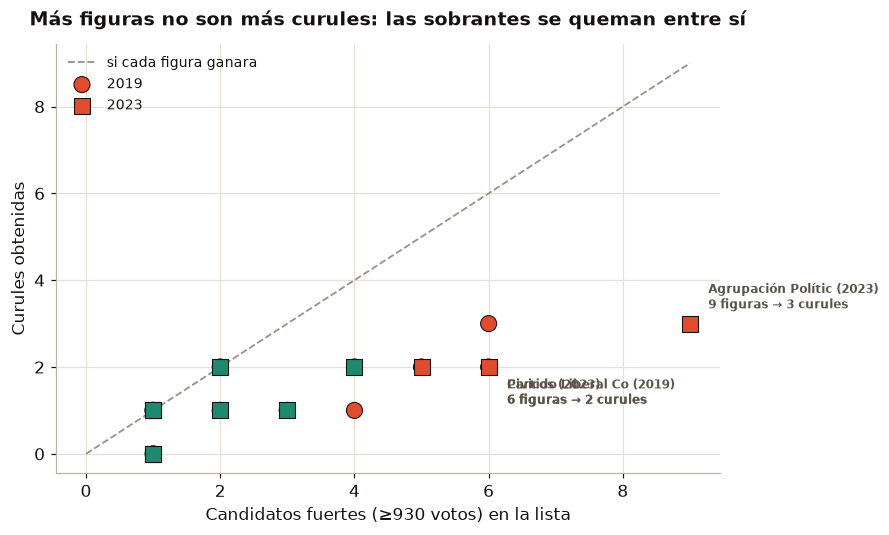

In [23]:
# Gráfico: figuras vs curules — la diagonal que nunca se alcanza
fig, ax = plt.subplots(figsize=(8.2, 5))
mx = int(AB.F.max())
ax.plot([0, mx], [0, mx], color=MUTED, ls="--", lw=1.2, label="si cada figura ganara")
for y, mk in [(2019, "o"), (2023, "s")]:
    d = AB[(AB.anio==y) & ((AB.gano) | (AB.F>0))]
    ax.scatter(d.F, d.curules, s=110, zorder=3, marker=mk,
               edgecolor=INK, linewidth=.7,
               color=[VERM if q >= 3 else TEAL for q in d.quemados],
               label=f"{y}")
peor = AB.sort_values("quemados", ascending=False).head(3)
for k, (_, r) in enumerate(peor.iterrows()):
    ax.annotate(f"{r.lista.title()[:18]} ({int(r.anio)})\n{int(r.F)} figuras → {int(r.curules)} curules",
                (r.F, r.curules), fontsize=7.8, fontweight="bold", color="#5B5347",
                xytext=(12, [10, -24, -24][k]), textcoords="offset points")
ax.set_xlabel("Candidatos fuertes (≥930 votos) en la lista")
ax.set_ylabel("Curules obtenidas")
ax.set_title("Más figuras no son más curules: las sobrantes se queman entre sí",
             fontsize=12.5, fontweight="bold")
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()


**Hallazgo 15 — Dos de cada tres figuras no llegan al Concejo, y casi siempre por culpa de su propia lista.** `Nivel A/B`

De **75** candidaturas que superaron los 930 votos en los dos ciclos, solo **33** salieron electas. De las **42 quemadas**, **38 lo fueron por sobrecarga de su propia lista**: su lista no tenía tantas curules como figuras. Solo 4 se quemaron porque la lista entera se quedó sin curul.

El caso extremo: En Marcha 2023 llevó **9 figuras**, sacó **3 curules** y quemó **6**. Cambio Radical 2019: 6 figuras, 3 curules, 3 quemadas.

*Lo que NO significa:* no dice que esas listas hubieran hecho más curules repartiendo a sus figuras en otras listas — eso depende de a dónde se hubieran ido sus votos, que no es observable. Lo que el dato sí muestra es que, **dentro de la lista**, la figura número N+1 no añade una curul: añade un competidor por las mismas N.


### 8.8 Si ARMAS la lista: cómo ensamblar para maximizar curules

Reglas derivadas solo de patrones que **replican en los dos ciclos**:

1. **Fija el objetivo en votos, no en nombres.** Una curul cuesta una cifra repartidora: 4.412 en 2019, 4.042 en 2023. Para N curules, ensambla **N × cifra**, con margen.
2. **Necesitas al menos una figura que llegue al piso (~23 % de la cifra).** Sin ella, 0 de 15 listas abiertas sacaron curul en dos ciclos. Es condición necesaria.
3. **Una figura sola no basta: ponle banca.** Con un fuerte, 0 de 4 listas con banca ≤6 sacaron curul y 5 de 5 con banca ≥7 sí. La banca es lo que convierte una figura en una curul.
4. **La segunda figura vale más que la quinta.** Pasar de 1 a 2 fuertes mueve la tasa de 5/9 a 16/16. Pasar de 3 a 9 no agregó curules: quemó 6 figuras (En Marcha 2023).
5. **Dimensiona con la tasa de cambio.** 1 curul ≈ 3 figuras ≈ 6 medios ≈ 24 campañas. Para 2 curules sin desperdicio: ~2 anclas + banca ancha, no 6 figuras compitiendo.
6. **No esperes que separar a las figuras por comunas te dé más.** El solapamiento entre figuras de una misma lista es ~0,77 y no hay evidencia de que reducirlo produzca más curules. El territorio sirve para conseguir votos, no para evitar la canibalización.

### 8.9 Si quieres GANAR un puesto: en qué lista entrar

Ganar exige **dos condiciones a la vez**: que la lista supere la cifra, y que quedes en el **top-N** de esa lista. De ahí las dos trampas, ambas presentes en los dos ciclos:

- **Trampa 1 — entrar donde no eres top-N (38 casos).** Es la causa de casi todas las figuras quemadas. En 2019 Morgan Egea sacó **1.705 votos y no salió** — más que la mediana del electo de ese año (1.701). John Jairo García, 1.263 y afuera. Con esos mismos votos, en otra lista habrían entrado.
- **Trampa 2 — ser la figura de una lista que no llega (4 casos).** Kelly Ortiz, 1.472 votos, el 48 % de su lista, afuera: Vamos Unidos sumó 3.033 contra una cifra de 4.042.

**Qué mirar antes de firmar, en orden:**

1. **¿La lista va a superar la cifra?** Cuenta figuras y banca: con ≥2 figuras es casi seguro; con 1 figura, exige ver una banca de 7 o más candidaturas con campaña real.
2. **¿Cuántos van a quedar por encima de mí?** Si la lista hará ~2 curules y ya hay 3 figuras más fuertes que tú, tu voto no te alcanza aunque sea alto.
3. **La regla corta:** con 1.000–1.400 votos entras **si el número de compañeros más fuertes que tú es menor que las curules que hará la lista**. Elige por *cuántos van a estar por encima de mí*, no por el tamaño o la fama de la lista.

**Ser el número 1 de una lista mediana que hace 1 o 2 curules gana a ser el número 4 de una grande.**


## 9. El sistema de partidos visto desde las comunas

La sección anterior trató la lista como una estructura de candidatos. Falta preguntarse qué es la **etiqueta** del partido en Barrancabermeja: ¿arrastra voto propio, hay comunas fieles a una marca, se está fragmentando el voto?


In [24]:
# --- 9.1 ¿Cuánto cambia el voto entre partidos, comuna por comuna? ---
# Índice de Pedersen: mitad de la suma de cambios absolutos en la cuota de cada lista.
vmc = pd.read_csv(ANAL/"votos_mesa.csv", encoding="utf-8-sig",
                  usecols=["anio","corporacion","territorio","nombre_partido",
                           "tipo_opcion","es_voto_valido","votos"])
vmc = vmc[(vmc.corporacion=="CONCEJO") & (vmc.es_voto_valido)]

pc  = vmc.groupby(["anio","territorio","nombre_partido"], as_index=False).votos.sum()
tt  = pc.groupby(["anio","territorio"], as_index=False).votos.sum().rename(columns={"votos":"T"})
pc  = pc.merge(tt, on=["anio","territorio"]); pc["sh"] = 100*pc.votos/pc["T"]

ped = {}
for t in URB:
    a = pc[(pc.anio==2019) & (pc.territorio==t)].set_index("nombre_partido").sh
    b = pc[(pc.anio==2023) & (pc.territorio==t)].set_index("nombre_partido").sh
    a, b = a.align(b, fill_value=0)
    ped[t] = float(np.abs(a-b).sum()/2)
PED = pd.Series(ped).sort_values(ascending=False)

print("VOLATILIDAD DEL VOTO ENTRE LISTAS, Concejo 2019 → 2023 (índice de Pedersen)")
print("0 = ninguna lista cambió su cuota · 100 = recambio total\n")
for t, v in PED.items():
    print(f"  {t:12} {v:>5.1f}")
print(f"\n  Promedio ciudad {PED.mean():.1f} · rango {PED.min():.1f}–{PED.max():.1f} "
      f"(apenas {PED.max()-PED.min():.1f} puntos entre la más y la menos volátil)")


VOLATILIDAD DEL VOTO ENTRE LISTAS, Concejo 2019 → 2023 (índice de Pedersen)
0 = ninguna lista cambió su cuota · 100 = recambio total

  COMUNA 2      92.4
  COMUNA 1      92.3
  COMUNA 6      92.2
  COMUNA 7      91.5
  COMUNA 3      91.2
  COMUNA 4      90.3
  COMUNA 5      89.7

  Promedio ciudad 91.4 · rango 89.7–92.4 (apenas 2.7 puntos entre la más y la menos volátil)


In [25]:
# --- 9.2 ¿Es volatilidad real o recambio de etiquetas? ---
lst19 = set(pe[pe.anio==2019].nombre_partido); lst23 = set(pe[pe.anio==2023].nombre_partido)
ambas = lst19 & lst23
print(f"Listas que compitieron en 2019 : {len(lst19)}")
print(f"Listas que compitieron en 2023 : {len(lst23)}")
print(f"Listas presentes en AMBOS años : {len(ambas)}  -> {', '.join(sorted(ambas))}\n")
for y, s in [(2019, pe[pe.anio==2019]), (2023, pe[pe.anio==2023])]:
    sh = 100*s[s.nombre_partido.isin(ambas)].votos.sum()/s.votos.sum()
    print(f"  Voto que fue a listas presentes en ambos años, {y}: {sh:.1f}%")

c19 = set(ce[ce.anio==2019].nombre_candidato); c23 = set(ce[ce.anio==2023].nombre_candidato)
rep = c19 & c23
r   = ce[ce.nombre_candidato.isin(rep)]
pa  = r.pivot_table(index="nombre_candidato", columns="anio",
                    values="nombre_partido", aggfunc="first").dropna()
cam = int((pa[2019] != pa[2023]).sum())
print(f"\nCandidatos que se presentaron en los dos ciclos: {len(rep)}")
print(f"  de ellos, cambiaron de partido: {cam}  ({100*cam/len(pa):.0f}%)")

pv = r.pivot_table(index="nombre_candidato", columns="anio", values="votos", aggfunc="sum").dropna()
pv["dif"] = pv[2023] - pv[2019]
print(f"  subieron su votación: {int((pv.dif>0).sum())} · bajaron: {int((pv.dif<0).sum())} "
      f"· cambio mediano {pv.dif.median():+,.0f} votos")


Listas que compitieron en 2019 : 18
Listas que compitieron en 2023 : 25
Listas presentes en AMBOS años : 1  -> PARTIDO LIBERAL COLOMBIANO

  Voto que fue a listas presentes en ambos años, 2019: 11.3%
  Voto que fue a listas presentes en ambos años, 2023: 8.4%

Candidatos que se presentaron en los dos ciclos: 71
  de ellos, cambiaron de partido: 68  (96%)
  subieron su votación: 28 · bajaron: 42 · cambio mediano -23 votos


        listas  nº efectivo  candidatos  voto mediano
------------------------------------------------------
  2019      18         12.8         275           178
  2023      25         16.0         359           113


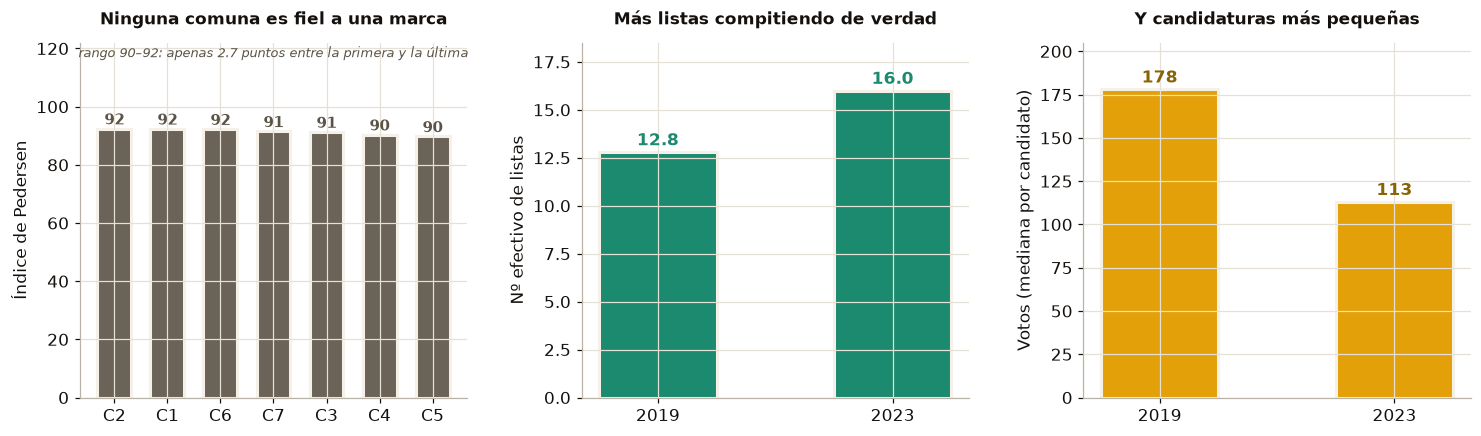

In [26]:
# --- 9.3 Fragmentación: ¿se está atomizando la competencia? ---
print(f"{'':6} {'listas':>7} {'nº efectivo':>12} {'candidatos':>11} {'voto mediano':>13}")
print("-"*54)
frag = {}
for y in (2019, 2023):
    s  = pe[pe.anio==y]; sh = s.votos/s.votos.sum()
    nef = 1/float((sh**2).sum())
    cs  = ce[ce.anio==y]
    frag[y] = (len(s), nef, len(cs), cs.votos.median())
    print(f"{y:>6} {len(s):>7} {nef:>12.1f} {len(cs):>11} {cs.votos.median():>13.0f}")

# Tres paneles, cada uno con UNA sola medida y su propia escala.
fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.1))

ax = axes[0]
x = np.arange(len(PED))
# Color uniforme: el hallazgo es precisamente que no hay comuna distinta.
ax.bar(x, PED.values, .64, color="#6B6358", edgecolor=PAPER, linewidth=2)
for xi, v in enumerate(PED.values):
    ax.text(xi, v+1.5, f"{v:.0f}", ha="center", fontsize=9.5, fontweight="bold", color="#5B5347")
ax.set_xticks(x); ax.set_xticklabels([t.replace("COMUNA ","C") for t in PED.index])
ax.set_ylim(0, 122); ax.set_ylabel("Índice de Pedersen")
ax.annotate(f"rango {PED.min():.0f}–{PED.max():.0f}: apenas {PED.max()-PED.min():.1f} puntos "
            "entre la primera y la última",
            xy=(.5, .99), xycoords="axes fraction", ha="center", va="top",
            fontsize=8.6, color="#5B5347", style="italic")
ax.set_title("Ninguna comuna es fiel a una marca", fontsize=11, fontweight="bold")

ax = axes[1]
xx = np.arange(2); nef = [frag[2019][1], frag[2023][1]]
ax.bar(xx, nef, .5, color=TEAL, edgecolor=PAPER, linewidth=2)
for xi, v in zip(xx, nef):
    ax.text(xi, v+.35, f"{v:.1f}", ha="center", fontsize=11, fontweight="bold", color=TEAL)
ax.set_xticks(xx); ax.set_xticklabels(["2019", "2023"])
ax.set_ylim(0, 18.5); ax.set_ylabel("Nº efectivo de listas")
ax.set_title("Más listas compitiendo de verdad", fontsize=11, fontweight="bold")

ax = axes[2]
med = [frag[2019][3], frag[2023][3]]
ax.bar(xx, med, .5, color=OCHRE, edgecolor=PAPER, linewidth=2)
for xi, v in zip(xx, med):
    ax.text(xi, v+4, f"{v:.0f}", ha="center", fontsize=11, fontweight="bold", color="#8A6204")
ax.set_xticks(xx); ax.set_xticklabels(["2019", "2023"])
ax.set_ylim(0, 205); ax.set_ylabel("Votos (mediana por candidato)")
ax.set_title("Y candidaturas más pequeñas", fontsize=11, fontweight="bold")

plt.tight_layout(); plt.show()


**Hallazgo 16 — La etiqueta de partido no arrastra voto: es un vehículo que se alquila cada elección.** `Nivel A/B`

Tres mediciones apuntan a lo mismo:

- **De las 18 listas de 2019 y las 25 de 2023, solo una compitió en ambas** (el Partido Liberal). Las listas que existieron en los dos ciclos recibieron el **11,3 %** del voto en 2019 y el **8,4 %** en 2023.
- **El 96 % de los candidatos que se presentaron en los dos ciclos (68 de 71) lo hizo bajo un partido distinto.**
- La volatilidad entre listas (índice de Pedersen) es de **91,4 en promedio**, y va de **89,7 a 92,4** — es decir, prácticamente la misma en las siete comunas. **No hay comuna fiel a una marca.**

La combinación es concluyente: si casi ninguna etiqueta sobrevive de un ciclo al siguiente, y casi todos los candidatos cambian de etiqueta, entonces el voto que se mueve no está siguiendo a los partidos. Esto da un mecanismo al Hallazgo 6 (la geografía local del Liberal no se parece a la del Senado, r = −0,07): **no es que la gente vote distinto al partido en lo local, es que en lo local la etiqueta casi no existe como identidad continua.**

Al mismo tiempo la competencia se está fragmentando: el número efectivo de listas pasó de **12,8 a 16,0**, los candidatos de 275 a 359, y el voto mediano por candidato cayó de **178 a 113**.

*Lo que NO significa:* un Pedersen de 91 no significa que 91 % de los votantes cambiara de opinión. Como las etiquetas mismas desaparecen y se crean, el índice mide **recambio de la oferta** tanto o más que cambio de preferencias. Es justamente ese punto el que sostiene el hallazgo: lo que rota es la oferta partidaria, no necesariamente el electorado.

**Para 2027:** la etiqueta bajo la que se compite no hereda votos del ciclo anterior. Para una lista nueva eso es una buena noticia (no parte en desventaja); para quien cuente con el "voto del partido", es una advertencia.


,roll_2019,roll_2023,cambio
comuna,,,
COMUNA 1,0.73,2.10,1.37
COMUNA 2,0.88,1.13,0.25
COMUNA 3,1.86,2.18,0.32
COMUNA 4,1.83,1.42,-0.41
COMUNA 5,1.70,2.12,0.42
COMUNA 6,2.10,2.45,0.35
COMUNA 7,1.48,2.76,1.28


Roll-off subió en 6 de las 7 comunas urbanas.
Mayor fuga de voto al Concejo en 2023: COMUNA 7 (2.76%)
Correlación del roll-off entre ciclos: +0.35  -> débil: no es un rasgo fijo de cada comuna.


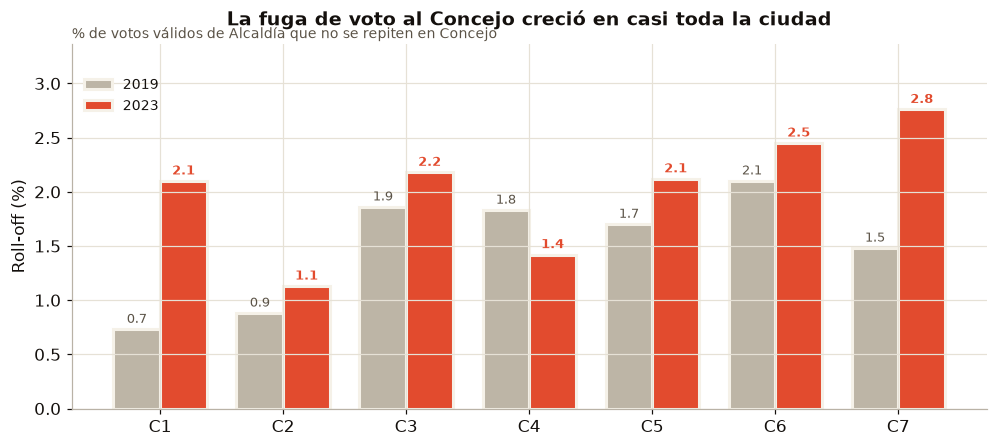

In [27]:
# --- 9.4 Roll-off por comuna: ¿dónde se pierde el voto al Concejo? ---
# Se recarga incluyendo ALCALDE (las cargas anteriores filtraban solo CONCEJO)
vm_ac = pd.read_csv(ANAL/"votos_mesa.csv", encoding="utf-8-sig",
                    usecols=["anio","corporacion","territorio","es_voto_valido","votos"])
ro = (vm_ac[vm_ac.es_voto_valido & vm_ac.corporacion.isin(["ALCALDE","CONCEJO"])]
        .groupby(["anio","corporacion","territorio"], as_index=False).votos.sum())
filas = []
for t in URB:
    f = {"comuna": t}
    for y in (2019, 2023):
        a = ro[(ro.anio==y)&(ro.corporacion=="ALCALDE")&(ro.territorio==t)].votos.sum()
        c = ro[(ro.anio==y)&(ro.corporacion=="CONCEJO")&(ro.territorio==t)].votos.sum()
        f[f"roll_{y}"] = round(100*(a-c)/a, 2) if a else np.nan
    f["cambio"] = round(f["roll_2023"] - f["roll_2019"], 2)
    filas.append(f)
RO = pd.DataFrame(filas).set_index("comuna")
display(RO)
print(f"Roll-off subió en {int((RO.cambio>0).sum())} de las {len(RO)} comunas urbanas.")
print(f"Mayor fuga de voto al Concejo en 2023: {RO.roll_2023.idxmax()} ({RO.roll_2023.max():.2f}%)")
print(f"Correlación del roll-off entre ciclos: {np.corrcoef(RO.roll_2019, RO.roll_2023)[0,1]:+.2f}"
      "  -> débil: no es un rasgo fijo de cada comuna.")

fig, ax = plt.subplots(figsize=(9.2, 4.2))
x = np.arange(len(RO)); w = .38
ax.bar(x-w/2, RO.roll_2019, w, color="#BDB5A6", edgecolor=PAPER, linewidth=2, label="2019")
ax.bar(x+w/2, RO.roll_2023, w, color=VERM,      edgecolor=PAPER, linewidth=2, label="2023")
for xi, (a, b) in enumerate(zip(RO.roll_2019, RO.roll_2023)):
    ax.text(xi-w/2, a+.06, f"{a:.1f}", ha="center", fontsize=8.5, color="#5B5347")
    ax.text(xi+w/2, b+.06, f"{b:.1f}", ha="center", fontsize=8.5, fontweight="bold", color=VERM)
ax.set_xticks(x); ax.set_xticklabels([c.replace("COMUNA ","C") for c in RO.index])
ax.set_ylabel("Roll-off (%)")
ax.set_ylim(0, RO[["roll_2019","roll_2023"]].to_numpy().max()*1.22)
ax.set_title("La fuga de voto al Concejo creció en casi toda la ciudad",
             fontsize=12.5, fontweight="bold")
ax.annotate("% de votos válidos de Alcaldía que no se repiten en Concejo",
            xy=(0, 1.015), xycoords="axes fraction", fontsize=9, color="#5B5347")
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, .94))
plt.tight_layout(); plt.show()


**Hallazgo 17 — La fuga de voto al Concejo creció en seis de las siete comunas.** `Nivel A/B`

Entre quienes ya estaban en el puesto de votación y marcaron Alcaldía, una fracción no deja voto válido de Concejo. Esa fracción **subió en 6 de 7 comunas** entre 2019 y 2023; la única excepción fue la Comuna 4.

El salto mayor está en la **Comuna 7** (1,48 % → 2,76 %), seguida de la **Comuna 1** (0,73 % → 2,10 %). En volumen, cada punto de roll-off en la ciudad equivale a más de mil votos válidos de Concejo que no se emiten.

La correlación entre ciclos es **+0,35**, débil: a diferencia del mapa de participación (Spearman 0,72, Hallazgo 2), el roll-off **no es un rasgo estable de cada comuna**. Es un margen que se mueve, y por eso es accionable: una lista que trabaje el "marque también Concejo" en su territorio está disputando votos que hoy se pierden.

*Lo que NO significa:* el roll-off agregado incluye voto en blanco y nulo de Concejo, no solo tarjetas sin marcar; y es una diferencia entre totales, no el seguimiento de personas concretas.


## 10. Mirada a 2027: escenarios (no pronósticos)

Con **solo dos ciclos territoriales** (2019 y 2023) no es honesto "predecir" 2027 con un modelo. Lo riguroso es plantear **escenarios** acotados y decir de qué dependen.


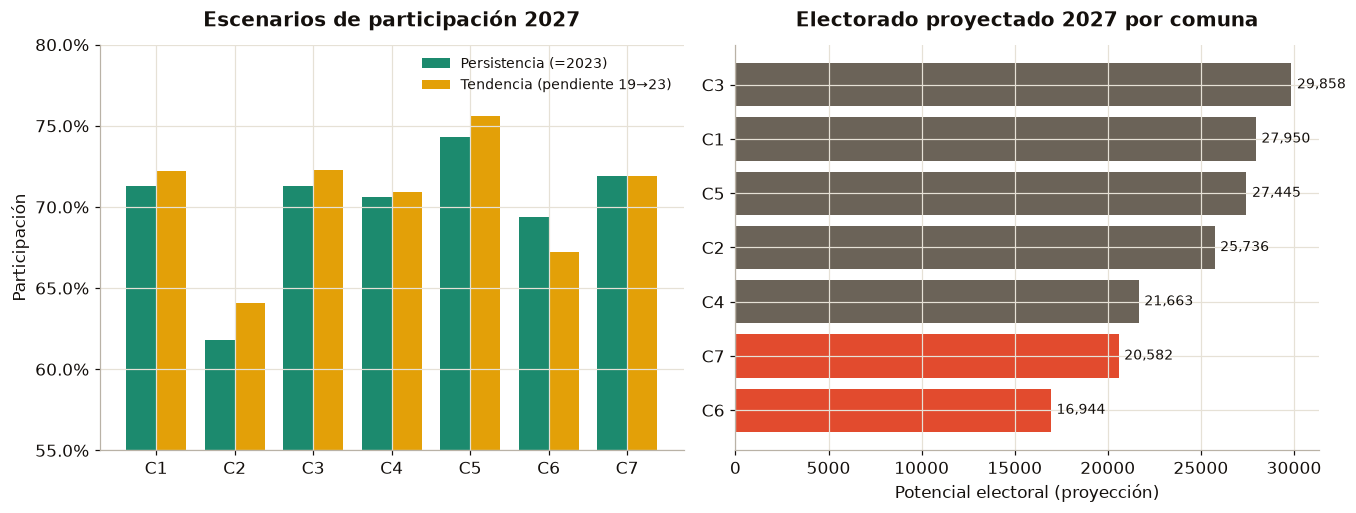

,2019,2023,Persistencia_2027,Tendencia_2027,censo_2026,censo_2027_proy,share_2027_%
territorio,,,,,,,
COMUNA 1,70.4,71.3,71.3,72.2,27890,27950,16.4
COMUNA 2,59.5,61.8,61.8,64.1,25773,25736,15.1
COMUNA 3,70.3,71.3,71.3,72.3,29369,29858,17.5
COMUNA 4,70.3,70.6,70.6,70.9,21430,21663,12.7
COMUNA 5,73.0,74.3,74.3,75.6,27015,27445,16.1
COMUNA 6,71.6,69.4,69.4,67.2,16255,16944,10.0
COMUNA 7,71.9,71.9,71.9,71.9,19309,20582,12.1


In [28]:
# Escenarios de participación territorial 2027 (persistencia vs tendencia)
esc = pd.DataFrame({"2019": p19.round(1), "2023": p23.round(1)})
esc["Persistencia_2027"] = esc["2023"]                              # se repite 2023
esc["Tendencia_2027"]    = (esc["2023"] + (esc["2023"]-esc["2019"])).clip(0,100).round(1)  # misma pendiente 4 años

# Electorado esperado 2027 por comuna: proyección log-lineal del censo 2019→2026 a 2027
import numpy as np
proj = {}
for c in URB:
    xs = np.array([2019,2023,2026]); ys = np.array([cen.loc[c,f"censo_{y}"] for y in xs], float)
    b = np.polyfit(xs, np.log(ys), 1)
    proj[c] = float(np.exp(np.polyval(b, 2027)))
esc["censo_2026"] = cen.censo_2026.astype(int)
esc["censo_2027_proy"] = pd.Series(proj).round(0).astype(int)
esc["share_2027_%"] = (esc["censo_2027_proy"]/esc["censo_2027_proy"].sum()*100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax = axes[0]
x = np.arange(len(URB)); w=.38
ax.bar(x-w/2, esc["Persistencia_2027"], w, color=TEAL,  label="Persistencia (=2023)")
ax.bar(x+w/2, esc["Tendencia_2027"],    w, color=OCHRE, label="Tendencia (pendiente 19→23)")
ax.set_xticks(x); ax.set_xticklabels([c.replace('COMUNA ','C') for c in URB])
ax.set_ylim(55,80); ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_title("Escenarios de participación 2027"); ax.set_ylabel("Participación"); ax.legend(frameon=False, fontsize=9)

ax = axes[1]
order = esc.sort_values("censo_2027_proy", ascending=True)
ax.barh([c.replace('COMUNA ','C') for c in order.index], order["censo_2027_proy"],
        color=[VERM if c in ("COMUNA 7","COMUNA 6") else "#6B6358" for c in order.index])
for yi,(c,v) in enumerate(order["censo_2027_proy"].items()):
    ax.text(v+300, yi, f"{v:,}", va="center", fontsize=9)
ax.set_title("Electorado proyectado 2027 por comuna"); ax.set_xlabel("Potencial electoral (proyección)")
plt.tight_layout(); plt.show()
display(esc)


**Hallazgo 10 — 2027 se juega sobre un mapa conocido, con la periferia pesando más.** `Nivel C (escenario)`

Bajo ambos escenarios, la jerarquía de comunas se mantiene: **Comuna 2 sigue siendo la de menor participación** y las Comunas **5, 7, 1, 3** las de mayor. La novedad es de **peso**: por crecimiento de censo, las Comunas **6 y 7** aportan una fracción creciente del electorado, así que una curul en 2027 se construye cada vez más mirando hacia la periferia.

*Lo que NO significa:* **no es un pronóstico.** Son dos escenarios aritméticos (persistencia y continuación de la tendencia) sobre dos puntos de datos; sirven para acotar expectativas, no para predecir un resultado. Choques locales (un candidato fuerte, una coyuntura) pueden mover la participación más que cualquiera de estas líneas.


## 11. Síntesis de hallazgos

| # | Hallazgo | Evidencia | Qué NO significa |
|---|----------|:---------:|------------------|
| 1 | Barranca participa más en lo **local** (~70 %) que en lo **nacional** (legislativas ~57–60 %, presidencial 64–69 %); la legislativa es la más baja y **cayó** de 2022 a 2026. | A/B | No es el patrón del país; es propio de Barranca. |
| 2 | El mapa de abstención por comuna es **estructural** (Spearman ≈ 0,72) y la **Comuna 2 es la más baja** en toda elección. | B | No son las mismas personas cada vez; es patrón de territorio. |
| 3 | Casi nadie vota "solo Alcaldía"; la fuga es de **votos válidos de Concejo** (~2 % en 2023, y creciendo). | A/B | Dato agregado, no individual; incluye blanco y nulo. |
| 4 | Hay **cuatro arquetipos** de comuna (apática que se encoge / periferia que crece / bastión / centro estable). | B | Perfiles descriptivos, no fijos. |
| 5 | El electorado se **corre hacia la periferia joven** (Comunas 6 y 7); la 2 se encoge. | A/B | Correlación ecológica; no prueba conducta individual. |
| **6** | **El voto al Concejo es personal, no ideológico**: la geografía local del Partido Liberal no se parece a su geografía al Senado (r = −0,07). | B | No mide clientelismo; con 2 partidos comparables es ilustrativo. |
| **7** | **Fortines**: un concejal (Ceferino Garay) sacó el **42 % de sus votos en un solo puesto** (HHI 7× la mediana). | A/B | Concentración ≠ irregularidad; mide dependencia territorial. |
| **8** | **Dos abstenciones**: Comunas 6 y 7 se activan solo para lo local (brecha ~18 pts); la Comuna 2 es apatía pareja (~9 pts). | B | Describe el patrón, no su causa. |
| **9** | **El piso del concejal es una fracción estable de la cifra**: 23,0 % en 2019 y 23,1 % en 2023 (1.013 y 932 votos). | A/B | Dos observaciones; es una regularidad a vigilar, no una constante demostrada. |
| **10** | **Sin ninguna figura ≥930, una lista abierta nunca sacó curul** (0/15, dos ciclos). **Con dos o más, siempre** (16/16). | B | Describe 31 listas observadas; correlación estructural, no ley causal. |
| **11** | Con **una sola figura**, decide la banca: banca ≤6 → 0/4 curules; banca ≥7 → 5/5. Separación sin solapamiento en ambos ciclos. | B | Nueve listas; lo robusto es la dirección, no el corte exacto en 7. |
| **12** | **La tasa de cambio entre tipos de candidato es estable**: 1 curul ≈ 3 figuras ≈ 6 medios ≈ 24 campañas, casi igual en los dos ciclos. | B | Medias por rango; no es una función lineal de suma. |
| **13** | **Cuatro formas de fracaso**; las dos que replican son las caras del mismo error: figura sin banca, o banca sin figura. | B | Cortes elegidos sobre estos mismos datos; describe la muestra. |
| **14** | **La geografía del voto de una figura NO predice si sale electa** (HHI 0,148 vs 0,148). Las figuras de una lista se solapan ~0,77: compiten en el mismo territorio. | B (nulo) | No dice que el territorio no importe para hacer campaña. |
| **15** | **42 de 75 figuras se quemaron; 38 por sobrecarga de su propia lista.** En Marcha 2023: 9 figuras → 3 curules. | A/B | No prueba que repartidas en otras listas habrían ganado. |
| **16** | **La etiqueta de partido no arrastra voto**: solo 1 lista compitió en ambos ciclos y **96 % de los candidatos repetidores cambió de partido**. Volatilidad ~91 e igual en las 7 comunas. | A/B | El Pedersen mide recambio de la oferta tanto como cambio de preferencias. |
| **17** | **El roll-off creció en 6 de 7 comunas**; no es rasgo fijo de cada una (r = +0,35), por eso es accionable. | A/B | Incluye blanco y nulo; es diferencia de totales, no seguimiento de personas. |
| 18 | 2027: **mismo orden** de participación, con la periferia pesando más. | C | Escenario, no pronóstico. |

## Implicaciones para 2027

- **Cómo se ensambla una lista.** Una figura que llegue al piso (~23 % de la cifra) es condición necesaria; una sola figura necesita detrás una banca de 7 o más candidaturas con campaña real. La segunda figura es la que más rinde; de la cuarta en adelante se queman.
- **Qué mira un candidato antes de firmar.** No el tamaño ni la fama de la lista, sino cuántos compañeros van a quedar por encima suyo frente a las curules que la lista va a hacer.
- **La etiqueta pesa poco.** Casi ninguna marca sobrevive de un ciclo al siguiente y el 96 % de los repetidores cambió de partido: una lista nueva no parte en desventaja, y quien cuente con el "voto del partido" se está apoyando en algo que los datos no muestran.
- **Dónde está el voto disponible.** La Comuna 2 concentra la mayor bolsa de abstención pero es la más difícil de activar; el electorado nuevo crece en las Comunas 6 y 7. Y el roll-off —voto que ya está en el puesto y no llega al Concejo— subió en casi toda la ciudad: es el voto más barato de recuperar.


## 12. Reproducibilidad, métodos y fuentes

**Fuentes** · Registraduría Nacional del Estado Civil (resultados E-14 y censo electoral) y CNE. Territoriales 2019 y 2023, Congreso 2022 y **2026**, Presidencia 2026 (1.ª y 2.ª vuelta). El Congreso 2026 se agregó desde el escrutinio por mesa y se guardó en `datos/procesados/participacion/participacion_congreso_2026.csv`. Procesamiento propio.

**Métodos** · Participación = votos depositados / potencial electoral. *Roll-off* = diferencia agregada Alcaldía–Concejo en tarjetas depositadas y válidas (misma jornada). Estabilidad del ranking = correlación de Spearman entre comunas. **Nacionalización** = correlación de Pearson, por puesto de votación, entre el % de un mismo partido al Concejo 2023 y al Senado 2022. **Fortines** = concentración territorial del voto de cada candidato (índice Herfindahl-Hirschman, HHI, y % del puesto más fuerte), desde los votos por candidato y puesto en `votos_mesa.csv` (302.979 registros). **Brecha de movilización** = participación territorial 2023 − legislativa 2026 por comuna. Proyección de censo a 2027 = ajuste log-lineal sobre 2019–2023–2026 (escenario). Escenarios de participación = persistencia (=2023) y tendencia (misma pendiente 2019→2023). Los agregados de nacionalización y fortines se guardaron en `datos/procesados/analisis/`.

**Método de la sección 8 (anatomía de listas)** · Se analizan las **43 listas al Concejo** de los dos ciclos (18 en 2019, 25 en 2023). Las **3 listas cerradas** (sin voto preferente observado) se excluyen de toda clasificación por tipo de candidato, porque en ellas no hay votación individual que contar; se reportan aparte. Los candidatos se clasifican por votos en seis rangos, con el umbral de "fuerte" fijado en el **piso empírico del concejal electo** de cada ciclo. Para evitar que un resultado dependa de esa elección, cada regla se prueba con **dos definiciones**: absoluta (≥930 en ambos años) y relativa (≥23 % de la cifra repartidora del año). **Ningún patrón se reporta agregando los dos ciclos**: cada celda y cada regla se muestran por año, y las que no se cumplen en ambos se marcan explícitamente como no replicadas o no verificables. El solapamiento territorial entre figuras de una misma lista se mide como el área común de sus perfiles de voto por territorio (suma de mínimos de las cuotas), promediada sobre todos los pares de la lista.

**Método de la sección 9 (sistema de partidos)** · Volatilidad = índice de Pedersen entre las cuotas de cada lista por territorio, Concejo 2019 vs 2023. Fragmentación = número efectivo de listas (Laakso-Taagepera, inverso de la suma de cuotas al cuadrado). Permanencia de etiquetas y cambio de partido = cruce por nombre de lista y por nombre de candidato entre los dos ciclos.

**Límites declarados** ·
- **El `n` es pequeño.** La sección 8 se apoya en 40 listas abiertas repartidas en dos ciclos; varias celdas de la matriz tienen n=1 o n=2 y se señalan como no verificables. Las reglas que se ofrecen son las que replican en ambos ciclos y bajo ambas definiciones de umbral; aun así son regularidades observadas en dos elecciones, no leyes.
- Los cortes de la tipología de fracasos se derivaron de estos mismos datos, así que la describen bien pero no están validados fuera de la muestra.
- El cruce de candidatos entre ciclos se hace por **nombre**; homónimos o cambios de registro podrían afectarlo marginalmente.
- El nivel por comuna de **Congreso 2022** tiene cobertura de puestos ~92 % (≈6 puestos sin comuna): se usa solo como referencia.
- Los análisis por comuna son **ecológicos**: describen territorios, no personas.
- Los **escenarios 2027** se apoyan en dos ciclos territoriales; son acotaciones, no predicciones.
- El censo 2026 corresponde al corte de la elección presidencial de 2026; para 2027 la Registraduría publicará un censo actualizado.

**Herramientas** · Python · pandas · numpy · matplotlib · scipy. Cada cifra del cuaderno se recomputa desde los archivos del proyecto.

---
*Laura Pérez · Ciencia de datos — Observatorio de Dinámicas Electorales de Barrancabermeja · @layape*
